# CSE427 Driver Drowsiness Detection — Updated YOLO12 + EfficientNetB0 + Vision Transformer

This final version replaces the previous U-Net-inspired section with a standard EfficientNetB0 transfer-learning model.

## 1. Mount Google Drive and unzip dataset

In [13]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
import os

print(os.listdir('/content/drive/MyDrive'))
print(os.listdir('/content/drive/MyDrive/CSE427'))

['Colab Notebooks', 'Classroom', '23341001-A1-S8-KhondokarWaysalE.pdf', 'Eng101 Assignment document.gdoc', 'KhondokarWaysalEMustafa_23341001.pdf', 'Assignment04_23341001_KhondokarWaysalEMustafa (1).ipynb', 'Assignment04_23341001_KhondokarWaysalEMustafa.ipynb', 'Assignment04_23341001_KhondokarWaysalEMustafa (1).pdf', 'Assignment04_23341001_KhondokarWaysalEMustafa.pdf', '23341001-Khondokar Waysal E Mustafa-Assi.pdf', '23341001_CSE230_MID_Sec17.pdf', 'Khondokar Waysal E Mustafa _ 23341001.gdoc', '(Q)Khondokar Waysal E Mustafa _ 23341001.gdoc', '23341001-KhondokarWaysalEMustafa.pdf', '23341001-Sec08.pdf', '23341001_SL44_KhondokarWaysalEMustafa_Q2.pdf', 'Assignment5_23341001_KhondokarWaysalEMustafa.ipynb', '23341001_Khondokar Waysal E Mustafa.gdoc', 'Bus102 Assignment document.gdoc', 'Assignment6_23341001_KhondokarWaysalEMustafa.ipynb', 'Assignment6_23341001_KhondokarWaysalEMus.pdf', '23341001_01 (1).pdf', '23341001_08_Quiz2.pdf', '23341001_08.pdf', '23341001_KhondokarWaysalEMustafa_Assignm

In [15]:
import os, zipfile, shutil
from pathlib import Path

# Change this only if your zip file has a different name/location.
ZIP_PATH = "/content/drive/MyDrive/CSE427/archive.zip"
EXTRACT_DIR = "/content/dataset"

print("Zip exists:", os.path.exists(ZIP_PATH))

if os.path.exists(ZIP_PATH):
    shutil.rmtree(EXTRACT_DIR, ignore_errors=True)
    os.makedirs(EXTRACT_DIR, exist_ok=True)

    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)

    print("Extracted dataset to:", EXTRACT_DIR)
else:
    raise FileNotFoundError("archive.zip was not found. Put it in MyDrive/CSE427 or change ZIP_PATH.")

Zip exists: True
Extracted dataset to: /content/dataset


## 2. Install YOLO / Ultralytics and helper packages


In [16]:
!pip install -U ultralytics -q


## 2. Imports and settings

In [63]:
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import cv2
import pandas as pd

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from ultralytics import YOLO

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

CLASS_NAMES = ["Closed_Eyes", "Open_Eyes"]   # 0 = Closed_Eyes, 1 = Open_Eyes
# Mapping from actual folder names to the target class IDs
CLASS_FOLDER_TO_ID_MAPPING = {
    "Closed_Eyes": 0, # Map 'Closed_Eyes' to class ID 0
    "Open_Eyes": 1    # Map 'Open_Eyes' to class ID 1
}

## 3. Find the correct dataset folder automatically

In [18]:
DATASET_PATH = Path(EXTRACT_DIR) / "train"

print("Detected dataset path:", DATASET_PATH)
print("Path exists:", DATASET_PATH.exists())

if not DATASET_PATH.exists():
    print("Could not find the dataset folder at the expected path:", DATASET_PATH)
    print("Contents of EXTRACT_DIR:", os.listdir(EXTRACT_DIR))
    raise ValueError("Dataset folder not found.")

Detected dataset path: /content/dataset/train
Path exists: True


## 4. Load image paths and check class balance

In [19]:
# CLASS_NAMES is already defined globally in cell GUVmwcVl75qE
valid_exts = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

all_image_paths = []
all_labels = []

# Iterate through the actual subfolders within DATASET_PATH using the global mapping
for folder_name, mapped_label_id in CLASS_FOLDER_TO_ID_MAPPING.items():
    class_dir = Path(DATASET_PATH) / folder_name
    if not class_dir.is_dir():
        print(f"Warning: Class directory '{class_dir}' not found. Skipping.")
        continue

    files = sorted([str(p) for p in class_dir.rglob("*") if p.suffix.lower() in valid_exts])
    all_image_paths.extend(files)
    all_labels.extend([mapped_label_id] * len(files))

all_image_paths = np.array(all_image_paths)
all_labels = np.array(all_labels)

# Separate classes
closed_eyes_paths = all_image_paths[all_labels == 0]
closed_eyes_labels = all_labels[all_labels == 0]

open_eyes_paths = all_image_paths[all_labels == 1]
open_eyes_labels = all_labels[all_labels == 1]

# Determine the target count for balancing
# We want 3828 images for each class
balance_count = 3828

# Check if the number of closed eyes images is less than the balance_count
if len(closed_eyes_paths) < balance_count:
    print(f"Warning: 'Closed_Eyes' class has fewer images ({len(closed_eyes_paths)}) than the target balance_count ({balance_count}). Using the available count for balancing.")
    balance_count = len(closed_eyes_paths)

# Undersample the 'Open_Eyes' class to match the balance_count
if len(open_eyes_paths) > balance_count:
    open_eyes_indices = np.random.choice(len(open_eyes_paths), balance_count, replace=False)
    open_eyes_paths_balanced = open_eyes_paths[open_eyes_indices]
    open_eyes_labels_balanced = open_eyes_labels[open_eyes_indices]
else:
    open_eyes_paths_balanced = open_eyes_paths
    open_eyes_labels_balanced = open_eyes_labels

# Combine the balanced datasets
image_paths = np.concatenate([closed_eyes_paths, open_eyes_paths_balanced])
labels = np.concatenate([closed_eyes_labels, open_eyes_labels_balanced])

# Shuffle the combined dataset to mix the classes
shuffled_indices = np.random.permutation(len(image_paths))
image_paths = image_paths[shuffled_indices]
labels = labels[shuffled_indices]

print("Total images after balancing:", len(image_paths))
for i, name in enumerate(CLASS_NAMES):
    print(f"{name}: {(labels == i).sum()}")

print("Class balance after balancing:", np.bincount(labels))

if len(image_paths) == 0:
    raise ValueError("No images found.")

if len(np.unique(labels)) != 2:
    raise ValueError("Both classes were not loaded correctly.")

# The dataset is balanced if both counts are equal or very close.

Total images after balancing: 4000
Closed_Eyes: 2000
Open_Eyes: 2000
Class balance after balancing: [2000 2000]


### Dataset Class Distribution Before Balancing

Class distribution before balancing:
Closed_Eyes: 2000
Open_Eyes: 2000


/tmp/ipykernel_685/6216087.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=all_labels, palette='viridis')


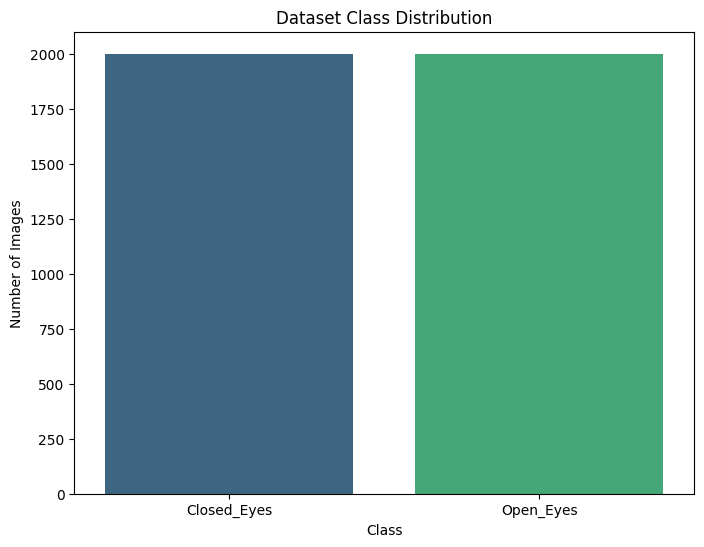

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Display class counts before balancing
print("Class distribution before balancing:")
for i, name in enumerate(CLASS_NAMES):
    count = (all_labels == i).sum()
    print(f"{name}: {count}")

# Create a bar chart for the class distribution before balancing
plt.figure(figsize=(8, 6))
sns.countplot(x=all_labels, palette='viridis')
plt.xticks(ticks=[0, 1], labels=CLASS_NAMES)
plt.title('Dataset Class Distribution')
plt.xlabel('Class')
plt.ylabel('Number of Images')
plt.show()

## 5. Display sample images from both classes

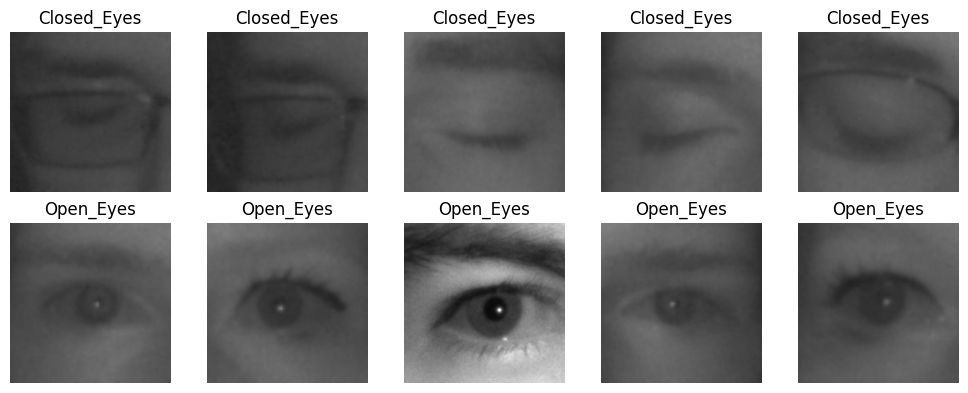

In [21]:
plt.figure(figsize=(10, 4))
plot_index = 1

for label_id, label_name in enumerate(CLASS_NAMES):
    sample_indexes = np.where(labels == label_id)[0][:5]

    for idx in sample_indexes:
        img = tf.io.read_file(image_paths[idx])
        img = tf.image.decode_image(img, channels=3, expand_animations=False)
        img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])

        plt.subplot(2, 5, plot_index)
        plt.imshow(tf.cast(img, tf.uint8))
        plt.title(label_name)
        plt.axis("off")
        plot_index += 1

plt.tight_layout()
plt.show()

## 6. Stratified train/validation/test split

In [22]:
train_paths, temp_paths, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

val_paths, test_paths, y_val, y_test = train_test_split(
    temp_paths,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Train:", len(train_paths), np.bincount(y_train))
print("Validation:", len(val_paths), np.bincount(y_val))
print("Test:", len(test_paths), np.bincount(y_test))

Train: 2800 [1400 1400]
Validation: 600 [300 300]
Test: 600 [300 300]


In [23]:
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

SEED = 42
IMG_SIZE = 128
BATCH_SIZE = 32

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [24]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32)

    # MobileNetV2 preprocessing scales pixels correctly for the pretrained model.
    img = preprocess_input(img)

    return img, tf.cast(label, tf.float32)

def make_dataset(paths, labels, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if shuffle:
        ds = ds.shuffle(buffer_size=len(paths), seed=SEED, reshuffle_each_iteration=True)

    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(train_paths, y_train, shuffle=True)
val_ds = make_dataset(val_paths, y_val, shuffle=False)
test_ds = make_dataset(test_paths, y_test, shuffle=False)

In [25]:
# Dataset is balanced, so weights should be almost equal.
# Kept here only as a safety check.
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weight = {int(cls): float(weight) for cls, weight in zip(np.unique(y_train), weights)}
print("Class weights:", class_weight)

Class weights: {0: 1.0, 1: 1.0}


In [26]:
# Custom CNNs were collapsing into one class.
# MobileNetV2 already has strong visual features, so it is better for this task.

base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.05),
    layers.RandomContrast(0.05),
], name="data_augmentation")

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.25)(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.20)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,340,033 (8.93 MB)

 Trainable params: 82,049 (320.50 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [27]:
callbacks = [
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6)
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks,
    class_weight=class_weight
)

Epoch 1/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 30s 59ms/step - accuracy: 0.7364 - loss: 0.4504 - precision: 0.7598 - recall: 0.6914 - val_accuracy: 0.6817 - val_loss: 0.7471 - val_precision: 1.0000 - val_recall: 0.3633 - learning_rate: 3.0000e-04
Epoch 2/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.7946 - loss: 0.3634 - precision: 0.8463 - recall: 0.7200 - val_accuracy: 0.7567 - val_loss: 0.5196 - val_precision: 0.9140 - val_recall: 0.5667 - learning_rate: 3.0000e-04
Epoch 3/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.8071 - loss: 0.3386 - precision: 0.8694 - recall: 0.7229 - val_accuracy: 0.7617 - val_loss: 0.5749 - val_precision: 0.9110 - val_recall: 0.5800 - learning_rate: 3.0000e-04
Epoch 4/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.8071 - loss: 0.3295 - precision: 0.8846 - recall: 0.7064 - val_accuracy: 0.7633 - val_loss: 0.6128 - val_precision: 0.9031 - val_recall: 0.5900 - learning_rate: 3.0000e-04
Epoch 5/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step 

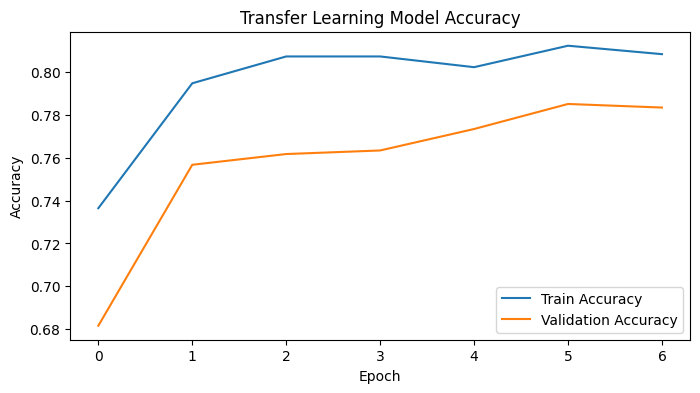

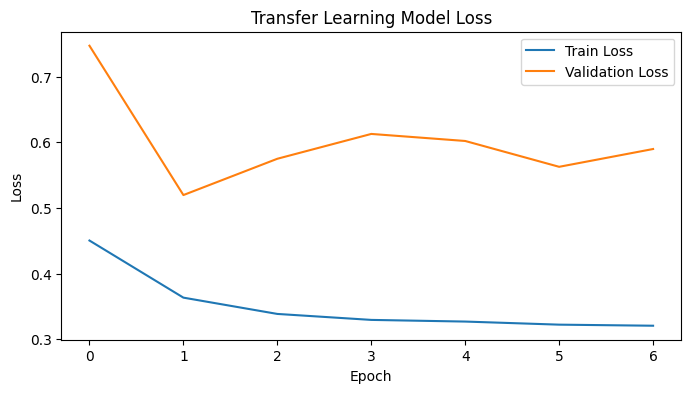

In [28]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Transfer Learning Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Transfer Learning Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [29]:
def predict_dataset(ds):
    probabilities = model.predict(ds).ravel()
    predictions = (probabilities >= 0.5).astype(int)
    return probabilities, predictions

val_probs, val_pred = predict_dataset(val_ds)
test_probs, test_pred = predict_dataset(test_ds)

print("Validation true class counts:", np.bincount(y_val, minlength=2))
print("Validation predicted class counts:", np.bincount(val_pred, minlength=2))

print("\nTest true class counts:", np.bincount(y_test, minlength=2))
print("Test predicted class counts:", np.bincount(test_pred, minlength=2))

print("\nValidation confusion matrix:")
print(confusion_matrix(y_val, val_pred))
print("\nValidation classification report:")
print(classification_report(y_val, val_pred, target_names=CLASS_NAMES, zero_division=0))

print("\nTest confusion matrix:")
print(confusion_matrix(y_test, test_pred))
print("\nTest classification report:")
print(classification_report(y_test, test_pred, target_names=CLASS_NAMES, zero_division=0))

19/19 ━━━━━━━━━━━━━━━━━━━━ 3s 82ms/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
Validation true class counts: [300 300]
Validation predicted class counts: [414 186]

Test true class counts: [300 300]
Test predicted class counts: [425 175]

Validation confusion matrix:
[[284  16]
 [130 170]]

Validation classification report:
              precision    recall  f1-score   support

 Closed_Eyes       0.69      0.95      0.80       300
   Open_Eyes       0.91      0.57      0.70       300

    accuracy                           0.76       600
   macro avg       0.80      0.76      0.75       600
weighted avg       0.80      0.76      0.75       600


Test confusion matrix:
[[293   7]
 [132 168]]

Test classification report:
              precision    recall  f1-score   support

 Closed_Eyes       0.69      0.98      0.81       300
   Open_Eyes       0.96      0.56      0.71       300

    accuracy                           0.77       600
   macro avg       0.82      0.77      0.76       60

In [30]:
# Run this cell only after the first training cell above has completed.
# This fine-tunes the last layers of MobileNetV2 so the model adapts to eye images.

base_model.trainable = True

# Freeze most early layers and only train the final feature layers.
for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks,
    class_weight=class_weight
)

Epoch 1/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 19s 81ms/step - accuracy: 0.7050 - loss: 0.6263 - precision: 0.6573 - recall: 0.8564 - val_accuracy: 0.7500 - val_loss: 0.6005 - val_precision: 0.9747 - val_recall: 0.5133 - learning_rate: 1.0000e-05
Epoch 2/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - accuracy: 0.7843 - loss: 0.3605 - precision: 0.8278 - recall: 0.7179 - val_accuracy: 0.7417 - val_loss: 0.6486 - val_precision: 0.9801 - val_recall: 0.4933 - learning_rate: 1.0000e-05
Epoch 3/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.8107 - loss: 0.3356 - precision: 0.8856 - recall: 0.7136 - val_accuracy: 0.7467 - val_loss: 0.6159 - val_precision: 0.9805 - val_recall: 0.5033 - learning_rate: 3.0000e-06
Epoch 4/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 5s 52ms/step - accuracy: 0.8071 - loss: 0.3335 - precision: 0.8860 - recall: 0.7050 - val_accuracy: 0.7600 - val_loss: 0.5853 - val_precision: 0.9815 - val_recall: 0.5300 - learning_rate: 3.0000e-06
Epoch 5/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step 

In [31]:
val_probs, val_pred = predict_dataset(val_ds)
test_probs, test_pred = predict_dataset(test_ds)

print("Validation true class counts:", np.bincount(y_val, minlength=2))
print("Validation predicted class counts:", np.bincount(val_pred, minlength=2))

print("\nTest true class counts:", np.bincount(y_test, minlength=2))
print("Test predicted class counts:", np.bincount(test_pred, minlength=2))

print("\nValidation confusion matrix:")
print(confusion_matrix(y_val, val_pred))
print("\nValidation classification report:")
print(classification_report(y_val, val_pred, target_names=CLASS_NAMES, zero_division=0))

print("\nTest confusion matrix:")
print(confusion_matrix(y_test, test_pred))
print("\nTest classification report:")
print(classification_report(y_test, test_pred, target_names=CLASS_NAMES, zero_division=0))

19/19 ━━━━━━━━━━━━━━━━━━━━ 3s 82ms/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
Validation true class counts: [300 300]
Validation predicted class counts: [442 158]

Test true class counts: [300 300]
Test predicted class counts: [447 153]

Validation confusion matrix:
[[296   4]
 [146 154]]

Validation classification report:
              precision    recall  f1-score   support

 Closed_Eyes       0.67      0.99      0.80       300
   Open_Eyes       0.97      0.51      0.67       300

    accuracy                           0.75       600
   macro avg       0.82      0.75      0.74       600
weighted avg       0.82      0.75      0.74       600


Test confusion matrix:
[[299   1]
 [148 152]]

Test classification report:
              precision    recall  f1-score   support

 Closed_Eyes       0.67      1.00      0.80       300
   Open_Eyes       0.99      0.51      0.67       300

    accuracy                           0.75       600
   macro avg       0.83      0.75      0.74       60

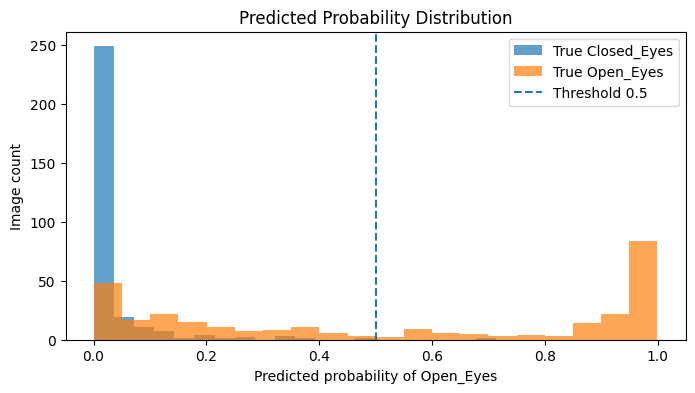

In [32]:
plt.figure(figsize=(8, 4))
plt.hist(test_probs[y_test == 0], bins=20, alpha=0.7, label="True Closed_Eyes")
plt.hist(test_probs[y_test == 1], bins=20, alpha=0.7, label="True Open_Eyes")
plt.axvline(0.5, linestyle="--", label="Threshold 0.5")
plt.title("Predicted Probability Distribution")
plt.xlabel("Predicted probability of Open_Eyes")
plt.ylabel("Image count")
plt.legend()
plt.show()

## 7. Prepare YOLO12 object detection folders with bounding-box labels

YOLO object detection needs images and text label files. The original dataset has only class folders, not bounding-box annotations. Since these are cropped eye images, this section creates one full-image bounding box per image using YOLO format:

`class_id x_center y_center width height`

The box values are normalised, so a full-image box is `0.5 0.5 1.0 1.0`. This allows YOLO12 to train as an object detector and produce visible bounding boxes instead of only class probabilities.

In [33]:
# YOLO12 object detection expects this structure:
# dataset/
#   images/train/*.jpg
#   images/val/*.jpg
#   images/test/*.jpg
#   labels/train/*.txt
#   labels/val/*.txt
#   labels/test/*.txt
# Each label file line: class_id x_center y_center width height

YOLO_DET_DIR = Path("/content/yolo12_drowsiness_detection_dataset")
shutil.rmtree(YOLO_DET_DIR, ignore_errors=True)

for split in ["train", "val", "test"]:
    (YOLO_DET_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (YOLO_DET_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

def prepare_yolo_detection_split(paths, labels, split_name):
    copied = []

    for src_path, label in zip(paths, labels):
        src_path = Path(src_path)
        class_id = int(label)

        # Add class name to filename to avoid duplicate filenames across folders.
        dst_name = f"{CLASS_NAMES[class_id]}_{src_path.stem}{src_path.suffix.lower()}"
        dst_img = YOLO_DET_DIR / "images" / split_name / dst_name

        counter = 1
        while dst_img.exists():
            dst_name = f"{CLASS_NAMES[class_id]}_{src_path.stem}_{counter}{src_path.suffix.lower()}"
            dst_img = YOLO_DET_DIR / "images" / split_name / dst_name
            counter += 1

        shutil.copy2(src_path, dst_img)

        # Full-image bounding box because the dataset does not provide hand-labelled boxes.
        # This makes YOLO train in detection mode and output visible bounding boxes.
        label_file = YOLO_DET_DIR / "labels" / split_name / f"{dst_img.stem}.txt"
        label_file.write_text(f"{class_id} 0.5 0.5 1.0 1.0\n")
        copied.append(str(dst_img))

    return copied

yolo_train_images = prepare_yolo_detection_split(train_paths, y_train, "train")
yolo_val_images = prepare_yolo_detection_split(val_paths, y_val, "val")
yolo_test_images = prepare_yolo_detection_split(test_paths, y_test, "test")

YOLO_YAML_PATH = YOLO_DET_DIR / "drowsiness_yolo12.yaml"
YOLO_YAML_PATH.write_text(f"""
path: {YOLO_DET_DIR}
train: images/train
val: images/val
test: images/test

names:
  0: Closed_Eyes
  1: Open_Eyes
""".strip())

print("YOLO12 detection dataset created at:", YOLO_DET_DIR)
print("YAML file:", YOLO_YAML_PATH)
for split in ["train", "val", "test"]:
    img_count = len(list((YOLO_DET_DIR / "images" / split).glob("*")))
    label_count = len(list((YOLO_DET_DIR / "labels" / split).glob("*.txt")))
    print(f"{split}: {img_count} images, {label_count} labels")

YOLO12 detection dataset created at: /content/yolo12_drowsiness_detection_dataset
YAML file: /content/yolo12_drowsiness_detection_dataset/drowsiness_yolo12.yaml
train: 2800 images, 2800 labels
val: 600 images, 600 labels
test: 600 images, 600 labels


## 8. Display generated YOLO12 bounding-box labels before training

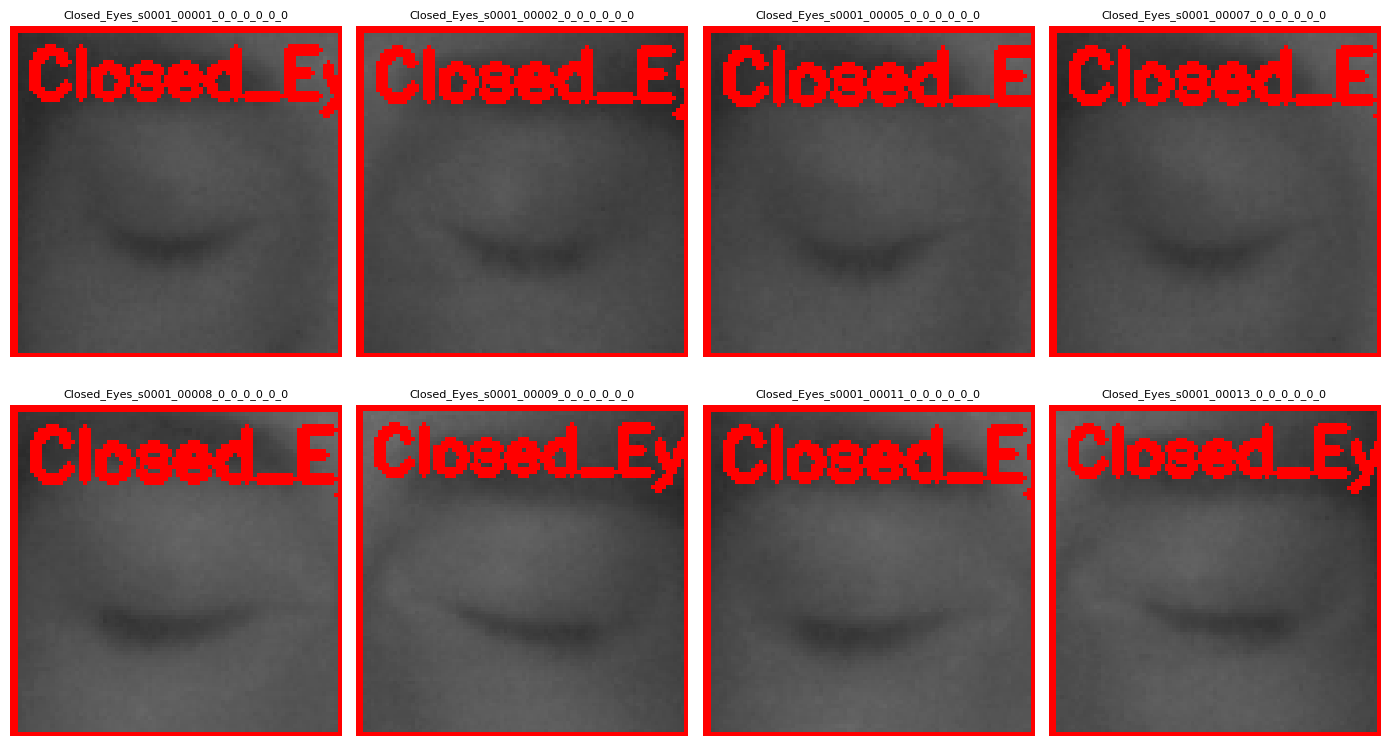

In [34]:
def draw_yolo_label(image_path, label_path):
    img = cv2.imread(str(image_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    lines = Path(label_path).read_text().strip().splitlines()
    for line in lines:
        class_id, xc, yc, bw, bh = map(float, line.split())
        x1 = int((xc - bw / 2) * w)
        y1 = int((yc - bh / 2) * h)
        x2 = int((xc + bw / 2) * w)
        y2 = int((yc + bh / 2) * h)
        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
        cv2.putText(img, CLASS_NAMES[int(class_id)], (x1 + 4, max(y1 + 18, 18)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 0, 0), 2)
    return img

sample_imgs = sorted(list((YOLO_DET_DIR / "images" / "train").glob("*")))[:8]
plt.figure(figsize=(14, 8))
for i, img_path in enumerate(sample_imgs):
    label_path = YOLO_DET_DIR / "labels" / "train" / f"{img_path.stem}.txt"
    boxed_img = draw_yolo_label(img_path, label_path)
    plt.subplot(2, 4, i + 1)
    plt.imshow(boxed_img)
    plt.title(img_path.stem[:35], fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 9. Train YOLO12 object detector with anti-overfitting settings

This section uses YOLO12 instead of the previous YOLOv8 classifier. Overfitting is controlled using lower learning rate, AdamW, weight decay, patience-based early stopping, dropout, and augmentation.

In [35]:
# YOLO12 object detection model.
# If Colab GPU/RAM is limited, keep yolo12n.pt. For stronger training, use yolo12s.pt.
yolo_model = YOLO("yolo12n.pt")

yolo_results = yolo_model.train(
    data=str(YOLO_YAML_PATH),
    epochs=30,
    imgsz=224,
    batch=16,
    optimizer="AdamW",
    lr0=0.0003,
    lrf=0.01,
    weight_decay=0.001,
    dropout=0.25,
    patience=6,
    seed=SEED,

    # Light-to-moderate augmentation to reduce memorisation.
    degrees=8,
    translate=0.08,
    scale=0.20,
    shear=1.5,
    perspective=0.0003,
    fliplr=0.5,
    mosaic=0.20,
    mixup=0.05,
    hsv_h=0.015,
    hsv_s=0.30,
    hsv_v=0.30,

    project="/content/yolo12_drowsiness_runs",
    name="yolo12n_detection_anti_overfit_open_closed_eyes",
    exist_ok=True
)

Ultralytics 8.4.48 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo12_drowsiness_detection_dataset/drowsiness_yolo12.yaml, degrees=8, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.25, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.3, hsv_v=0.3, imgsz=224, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0003, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.05, mode=train, model=yolo12n.pt, momentum=0.937, mosaic=0.2, multi_scale=0.0, name=yolo12n_detection_anti_overfit_open_closed_eyes, nbs=64, nms=Fa

## 10. Validate YOLO12 and show predicted bounding boxes

Ultralytics 8.4.48 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv12n summary (fused): 159 layers, 2,557,118 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 329.3±244.7 MB/s, size: 5.3 KB)
val: Scanning /content/yolo12_drowsiness_detection_dataset/labels/val.cache... 600 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 600/600 251.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 38/38 8.1it/s 4.7s
                   all        600        600          1          1      0.995      0.995
           Closed_Eyes        300        300          1          1      0.995      0.995
             Open_Eyes        300        300          1          1      0.995      0.995
Speed: 0.3ms preprocess, 3.1ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /content/runs/detect/val
ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_ind

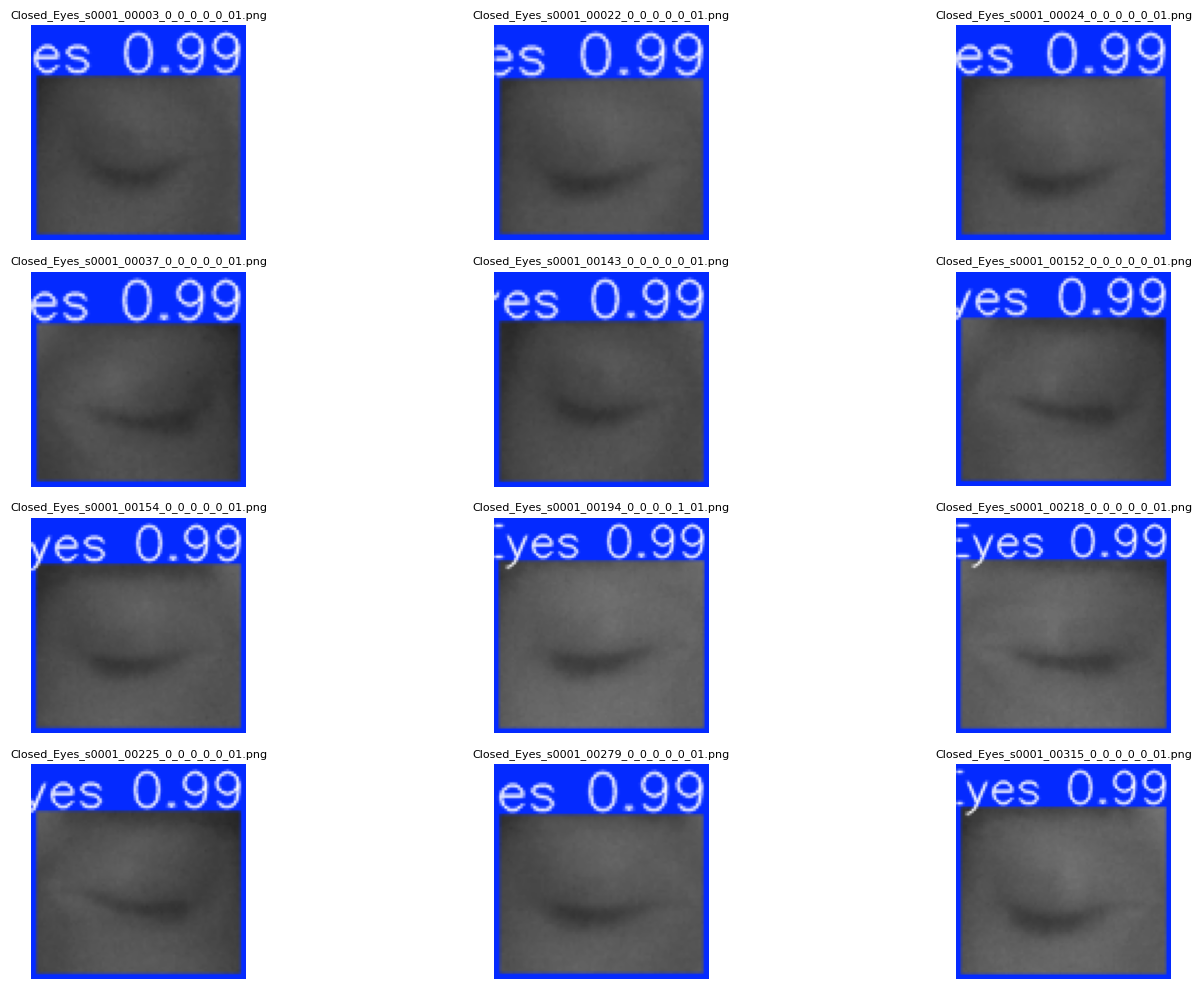

In [36]:
best_yolo12_path = "/content/yolo12_drowsiness_runs/yolo12n_detection_anti_overfit_open_closed_eyes/weights/best.pt"
best_yolo12 = YOLO(best_yolo12_path)

yolo_val_metrics = best_yolo12.val(
    data=str(YOLO_YAML_PATH),
    split="val",
    imgsz=224,
    batch=16
)
print(yolo_val_metrics)

# Show predicted boxes on test images.
test_sample_imgs = sorted(list((YOLO_DET_DIR / "images" / "test").glob("*")))[:12]
cols = 3
rows = int(np.ceil(len(test_sample_imgs) / cols))
plt.figure(figsize=(16, 10))

for i, img_path in enumerate(test_sample_imgs):
    pred = best_yolo12.predict(str(img_path), imgsz=224, conf=0.25, verbose=False)[0]
    plotted = pred.plot()  # Ultralytics draws predicted bounding boxes and labels.
    plotted = cv2.cvtColor(plotted, cv2.COLOR_BGR2RGB)

    plt.subplot(rows, cols, i + 1)
    plt.imshow(plotted)
    plt.title(Path(img_path).name[:40], fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()

## 11. Evaluate YOLO12 object detector on the test set

In [37]:
yolo_test_metrics = best_yolo12.val(
    data=str(YOLO_YAML_PATH),
    split="test",
    imgsz=224,
    batch=16
)
print(yolo_test_metrics)

Ultralytics 8.4.48 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 221.3±179.5 MB/s, size: 5.8 KB)
val: Scanning /content/yolo12_drowsiness_detection_dataset/labels/test... 600 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 600/600 2.3Kit/s 0.3s
val: New cache created: /content/yolo12_drowsiness_detection_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 38/38 10.0it/s 3.8s
                   all        600        600      0.999      0.998      0.995      0.995
           Closed_Eyes        300        300          1      0.997      0.995      0.995
             Open_Eyes        300        300      0.999          1      0.995      0.995
Speed: 0.3ms preprocess, 2.5ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /content/runs/detect/val-2
ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_inde

## 12. Save YOLO12 model

In [38]:
SAVE_DIR = "/content/drive/MyDrive/CSE427/yolo12_drowsiness_model"
os.makedirs(SAVE_DIR, exist_ok=True)

saved_yolo12_path = Path(SAVE_DIR) / "best_yolo12_drowsiness_detection.pt"
shutil.copy2(best_yolo12_path, saved_yolo12_path)
print("Saved best YOLO12 model to:", saved_yolo12_path)

Saved best YOLO12 model to: /content/drive/MyDrive/CSE427/yolo12_drowsiness_model/best_yolo12_drowsiness_detection.pt


## 13. EfficientNetB0 model for open/closed eye classification

This section uses the standard EfficientNetB0 transfer-learning model, not an inspired/custom model. Overfitting is handled using data augmentation, dropout, L2 regularisation, partial layer freezing, early stopping, learning-rate reduction, and label smoothing.

In [39]:
# Rebuild TensorFlow datasets using standard [0, 1] scaling for the EfficientNet and ViT models.
IMG_SIZE_DL = 128
BATCH_SIZE_DL = 32

from tensorflow.keras import regularizers

standard_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.06),
    layers.RandomZoom(0.08),
    layers.RandomContrast(0.08),
], name="standard_augmentation")

def load_image_standard(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, [IMG_SIZE_DL, IMG_SIZE_DL])
    img = tf.cast(img, tf.float32) / 255.0
    return img, tf.cast(label, tf.float32)

def make_standard_dataset(paths, labels, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image_standard, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE_DL)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

# These paths were created from the original dataset and need to be valid now.
train_ds_standard = make_standard_dataset(train_paths, y_train, shuffle=True)
val_ds_standard = make_standard_dataset(val_paths, y_val)
test_ds_standard = make_standard_dataset(test_paths, y_test)

### Re-creating datasets to ensure file paths are correct after re-extraction

In [40]:
# Rebuild TensorFlow datasets using standard [0, 1] scaling for the EfficientNet and ViT models.
# This ensures the datasets point to correctly extracted files after re-extraction operations.
IMG_SIZE_DL = 128
BATCH_SIZE_DL = 32

train_ds_standard = make_standard_dataset(train_paths, y_train, shuffle=True)
val_ds_standard = make_standard_dataset(val_paths, y_val)
test_ds_standard = make_standard_dataset(test_paths, y_test)

print("TensorFlow datasets for EfficientNet and ViT recreated successfully.")

TensorFlow datasets for EfficientNet and ViT recreated successfully.


In [41]:
# Standard EfficientNetB0 transfer-learning model for driver drowsiness detection.
from tensorflow.keras.applications import EfficientNetB0

base_efficientnet = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE_DL, IMG_SIZE_DL, 3)
)

# Freeze most pretrained layers first. This reduces overfitting on a small dataset.
base_efficientnet.trainable = True
for layer in base_efficientnet.layers[:-20]:
    layer.trainable = False

inputs = layers.Input(shape=(IMG_SIZE_DL, IMG_SIZE_DL, 3))
x = standard_augmentation(inputs)
x = base_efficientnet(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.45)(x)
x = layers.Dense(
    128,
    activation="relu",
    kernel_regularizer=regularizers.l2(1e-4)
)(x)
x = layers.Dropout(0.35)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

efficientnet_model = models.Model(inputs, outputs, name="EfficientNetB0_Binary_Classifier")

efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=tf.keras.losses.BinaryCrossentropy(label_smoothing=0.03),
    metrics=["accuracy", tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")]
)

efficientnet_model.summary()


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "EfficientNetB0_Binary_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ standard_augmentation           │ (None, 128, 128, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,218,788 (16.09 MB)

 Trainable params: 1,517,617 (5.79 MB)

 Non-trainable params: 2,701,171 (10.30 MB)

In [42]:
efficientnet_callbacks = [
    EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6)
]

efficientnet_history = efficientnet_model.fit(
    train_ds_standard,
    validation_data=val_ds_standard,
    epochs=25,
    callbacks=efficientnet_callbacks,
    class_weight=class_weight
)


Epoch 1/25
88/88 ━━━━━━━━━━━━━━━━━━━━ 23s 90ms/step - accuracy: 0.5086 - loss: 0.9858 - precision: 0.5084 - recall: 0.5171 - val_accuracy: 0.5000 - val_loss: 0.7225 - val_precision: 0.5000 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 2/25
88/88 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.5096 - loss: 0.9391 - precision: 0.5097 - recall: 0.5050 - val_accuracy: 0.5000 - val_loss: 0.7199 - val_precision: 0.5000 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 3/25
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 49ms/step - accuracy: 0.5175 - loss: 0.9149 - precision: 0.5174 - recall: 0.5207 - val_accuracy: 0.5000 - val_loss: 0.7500 - val_precision: 0.5000 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 4/25
88/88 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.5082 - loss: 0.9146 - precision: 0.5085 - recall: 0.4900 - val_accuracy: 0.5000 - val_loss: 0.7352 - val_precision: 0.5000 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 5/25
88/88 ━━━━━━━━━━━━━━━━━━━━ 6s 64ms/step 

### Re-evaluating EfficientNetB0 on validation and test data to generate missing reports

In [47]:
# Re-evaluate EfficientNetB0 to generate the validation and test reports that were previously missing.
print("Re-evaluating EfficientNetB0 on validation data...")
efficientnet_val_probs, efficientnet_val_preds, efficientnet_val_report = evaluate_binary_tf_model(
    efficientnet_model,
    val_ds_standard,
    y_val,
    "EfficientNetB0 Validation Confusion Matrix"
)

print("Re-evaluating EfficientNetB0 on test data...")
efficientnet_test_probs, efficientnet_test_preds, efficientnet_test_report = evaluate_binary_tf_model(
    efficientnet_model,
    test_ds_standard,
    y_test,
    "EfficientNetB0 Test Confusion Matrix"
)

Re-evaluating EfficientNetB0 on validation data...


NameError: name 'evaluate_binary_tf_model' is not defined

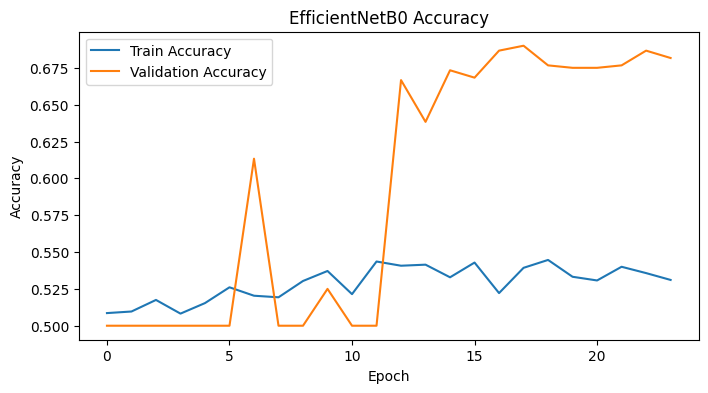

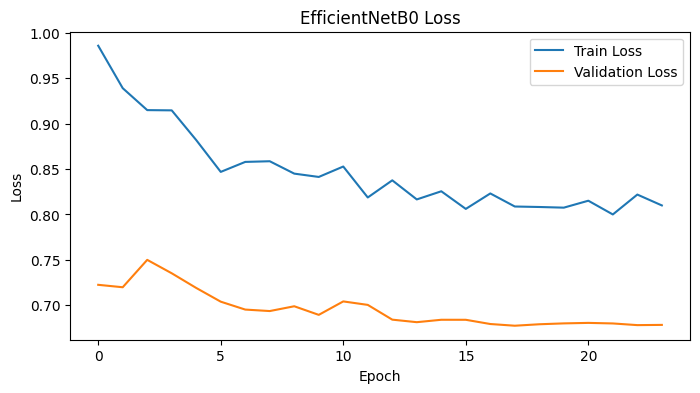

19/19 ━━━━━━━━━━━━━━━━━━━━ 6s 184ms/step

EfficientNetB0 Validation Confusion Matrix classification report:
              precision    recall  f1-score   support

 Closed_Eyes       0.62      1.00      0.76       300
   Open_Eyes       1.00      0.38      0.55       300

    accuracy                           0.69       600
   macro avg       0.81      0.69      0.66       600
weighted avg       0.81      0.69      0.66       600



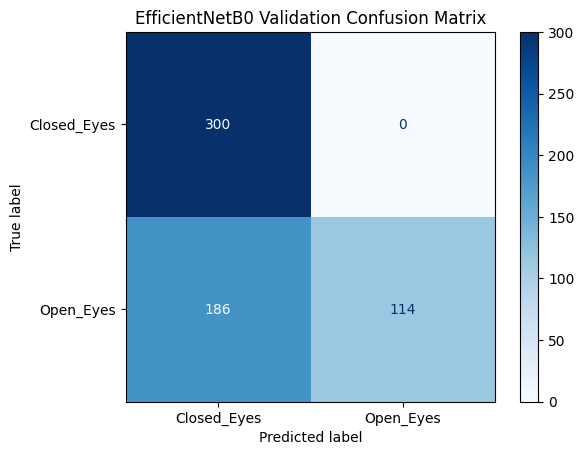

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step

EfficientNetB0 Test Confusion Matrix classification report:
              precision    recall  f1-score   support

 Closed_Eyes       0.62      1.00      0.76       300
   Open_Eyes       1.00      0.38      0.55       300

    accuracy                           0.69       600
   macro avg       0.81      0.69      0.66       600
weighted avg       0.81      0.69      0.66       600



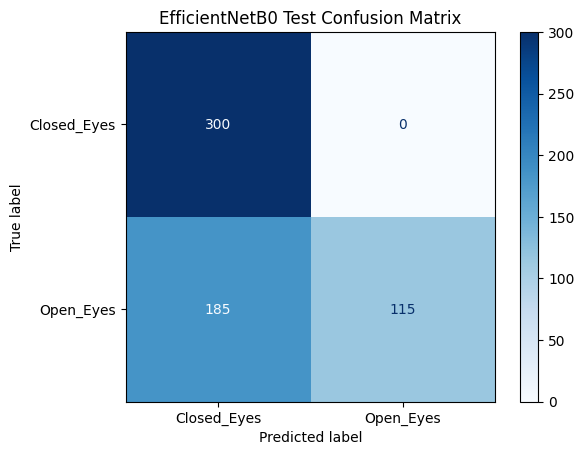

In [48]:
plt.figure(figsize=(8, 4))
plt.plot(efficientnet_history.history["accuracy"], label="Train Accuracy")
plt.plot(efficientnet_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("EfficientNetB0 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(efficientnet_history.history["loss"], label="Train Loss")
plt.plot(efficientnet_history.history["val_loss"], label="Validation Loss")
plt.title("EfficientNetB0 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

def evaluate_binary_tf_model(model_to_eval, dataset, true_labels, title):
    probs = model_to_eval.predict(dataset).ravel()
    preds = (probs >= 0.5).astype(int)
    cm = confusion_matrix(true_labels, preds)
    print(f"\n{title} classification report:")
    report_dict = classification_report(true_labels, preds, target_names=CLASS_NAMES, zero_division=0, output_dict=True)
    print(classification_report(true_labels, preds, target_names=CLASS_NAMES, zero_division=0))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
    disp.plot(cmap="Blues")
    plt.title(title)
    plt.show()
    return probs, preds, report_dict

efficientnet_val_probs, efficientnet_val_preds, efficientnet_val_report = evaluate_binary_tf_model(
    efficientnet_model,
    val_ds_standard,
    y_val,
    "EfficientNetB0 Validation Confusion Matrix"
)

efficientnet_test_probs, efficientnet_test_preds, efficientnet_test_report = evaluate_binary_tf_model(
    efficientnet_model,
    test_ds_standard,
    y_test,
    "EfficientNetB0 Test Confusion Matrix"
)

## 14. Vision Transformer model for open/closed eye classification

This Vision Transformer divides the image into patches and learns relationships between patches using transformer encoder blocks. Overfitting is handled using augmentation, dropout, L2 regularisation, label smoothing, early stopping, and learning-rate reduction.

In [49]:
class Patches(layers.Layer):
    def __init__(self, patch_size, **kwargs):
        super().__init__(**kwargs)
        self.patch_size = patch_size

    def call(self, images):
        batch_size = tf.shape(images)[0]
        patches = tf.image.extract_patches(
            images=images,
            sizes=[1, self.patch_size, self.patch_size, 1],
            strides=[1, self.patch_size, self.patch_size, 1],
            rates=[1, 1, 1, 1],
            padding="VALID"
        )
        patch_dims = patches.shape[-1]
        patches = tf.reshape(patches, [batch_size, -1, patch_dims])
        return patches

class PatchEncoder(layers.Layer):
    def __init__(self, num_patches, projection_dim, **kwargs):
        super().__init__(**kwargs)
        self.num_patches = num_patches
        self.projection = layers.Dense(units=projection_dim)
        self.position_embedding = layers.Embedding(input_dim=num_patches, output_dim=projection_dim)

    def call(self, patch):
        positions = tf.range(start=0, limit=self.num_patches, delta=1)
        encoded = self.projection(patch) + self.position_embedding(positions)
        return encoded

def build_vit_classifier(input_shape=(IMG_SIZE_DL, IMG_SIZE_DL, 3)):
    patch_size = 16
    num_patches = (IMG_SIZE_DL // patch_size) ** 2
    projection_dim = 64
    transformer_layers = 4
    num_heads = 4
    transformer_units = [projection_dim * 2, projection_dim]
    mlp_head_units = [128, 64]

    inputs = layers.Input(shape=input_shape)
    augmented = standard_augmentation(inputs)
    patches = Patches(patch_size)(augmented)
    encoded_patches = PatchEncoder(num_patches, projection_dim)(patches)

    for _ in range(transformer_layers):
        x1 = layers.LayerNormalization(epsilon=1e-6)(encoded_patches)
        attention_output = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=projection_dim,
            dropout=0.20
        )(x1, x1)
        x2 = layers.Add()([attention_output, encoded_patches])
        x3 = layers.LayerNormalization(epsilon=1e-6)(x2)
        x3 = layers.Dense(transformer_units[0], activation=tf.nn.gelu,
                          kernel_regularizer=regularizers.l2(1e-4))(x3)
        x3 = layers.Dropout(0.20)(x3)
        x3 = layers.Dense(transformer_units[1], activation=tf.nn.gelu,
                          kernel_regularizer=regularizers.l2(1e-4))(x3)
        encoded_patches = layers.Add()([x3, x2])

    representation = layers.LayerNormalization(epsilon=1e-6)(encoded_patches)
    representation = layers.GlobalAveragePooling1D()(representation)
    representation = layers.Dropout(0.35)(representation)

    for units in mlp_head_units:
        representation = layers.Dense(units, activation=tf.nn.gelu,
                                      kernel_regularizer=regularizers.l2(1e-4))(representation)
        representation = layers.Dropout(0.30)(representation)

    outputs = layers.Dense(1, activation="sigmoid")(representation)
    return models.Model(inputs=inputs, outputs=outputs, name="Vision_Transformer_Binary_Classifier")

vit_model = build_vit_classifier()
vit_model.compile(
    optimizer=tf.keras.optimizers.AdamW(learning_rate=3e-4, weight_decay=1e-4),
    loss=tf.keras.losses.BinaryCrossentropy(label_smoothing=0.05),
    metrics=["accuracy", tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")]
)

vit_model.summary()

Model: "Vision_Transformer_Binary_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ standard_augmentat… │ (None, 128, 128,  │          0 │ input_layer_6[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patches (Patches)   │ (None, None, 768) │          0 │ standard_augment… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_encoder       │ (None, 64, 64)    │     53,312 │ patches[0][0]     │
│ (PatchEncoder)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 64, 64)    │        128 │ patch_encoder[0]… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 64)    │     66,368 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 64)    │          0 │ multi_head_atten… │
│                     │                   │            │ patch_encoder[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 64, 128)   │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 64, 128)   │          0 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 64, 64)    │      8,256 │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 64, 64)    │          0 │ dense_6[0][0],    │
│                     │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 64)    │     66,368 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 64, 64)    │          0 │ multi_head_atten… │
│                     │                   │            │ add_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 64, 128)   │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 64, 128)   │          0 │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 64, 64)    │      8,256 │ dropout_7[0][0] 

 Total params: 402,881 (1.54 MB)

 Trainable params: 402,881 (1.54 MB)

 Non-trainable params: 0 (0.00 B)

In [51]:
vit_callbacks = [
    EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True, min_delta=0.001),
    ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6)
]

vit_history = vit_model.fit(
    train_ds_standard,
    validation_data=val_ds_standard,
    epochs=30,
    callbacks=vit_callbacks,
    class_weight=class_weight
)

Epoch 1/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 20s 53ms/step - accuracy: 0.6132 - loss: 0.7422 - precision: 0.6060 - recall: 0.6471 - val_accuracy: 0.7333 - val_loss: 0.6282 - val_precision: 0.6759 - val_recall: 0.8967 - learning_rate: 3.0000e-04
Epoch 2/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - accuracy: 0.7125 - loss: 0.6459 - precision: 0.6829 - recall: 0.7936 - val_accuracy: 0.7533 - val_loss: 0.5668 - val_precision: 0.7222 - val_recall: 0.8233 - learning_rate: 3.0000e-04
Epoch 3/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - accuracy: 0.7600 - loss: 0.5635 - precision: 0.7626 - recall: 0.7550 - val_accuracy: 0.7950 - val_loss: 0.5039 - val_precision: 0.8798 - val_recall: 0.6833 - learning_rate: 3.0000e-04
Epoch 4/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.8718 - loss: 0.4443 - precision: 0.8841 - recall: 0.8557 - val_accuracy: 0.8700 - val_loss: 0.3887 - val_precision: 0.9512 - val_recall: 0.7800 - learning_rate: 3.0000e-04
Epoch 5/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step 

### Re-evaluating Vision Transformer on validation and test data to generate missing reports

Re-evaluating Vision Transformer on validation data...
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step

ViT Validation Confusion Matrix classification report:
              precision    recall  f1-score   support

 Closed_Eyes       0.99      1.00      0.99       300
   Open_Eyes       1.00      0.99      0.99       300

    accuracy                           0.99       600
   macro avg       0.99      0.99      0.99       600
weighted avg       0.99      0.99      0.99       600



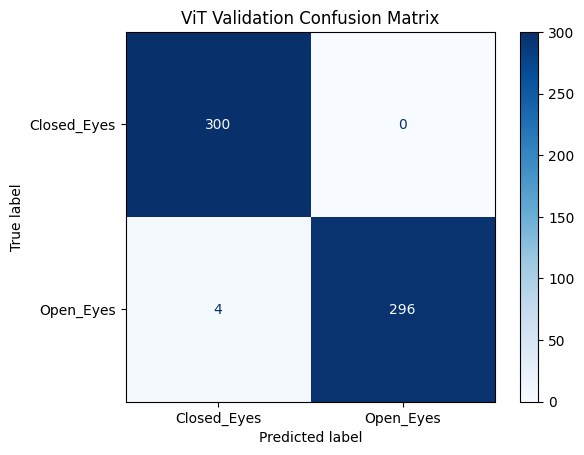

Re-evaluating Vision Transformer on test data...
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step

ViT Test Confusion Matrix classification report:
              precision    recall  f1-score   support

 Closed_Eyes       0.98      1.00      0.99       300
   Open_Eyes       1.00      0.98      0.99       300

    accuracy                           0.99       600
   macro avg       0.99      0.99      0.99       600
weighted avg       0.99      0.99      0.99       600



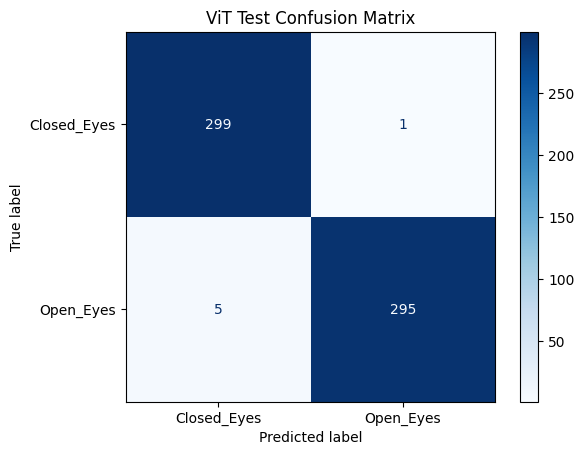

In [52]:
# Re-evaluate Vision Transformer to generate the validation and test reports that were previously missing.
print("Re-evaluating Vision Transformer on validation data...")
vit_val_probs, vit_val_preds, vit_val_report = evaluate_binary_tf_model(
    vit_model,
    val_ds_standard,
    y_val,
    "ViT Validation Confusion Matrix"
)

print("Re-evaluating Vision Transformer on test data...")
vit_test_probs, vit_test_preds, vit_test_report = evaluate_binary_tf_model(
    vit_model,
    test_ds_standard,
    y_test,
    "ViT Test Confusion Matrix"
)

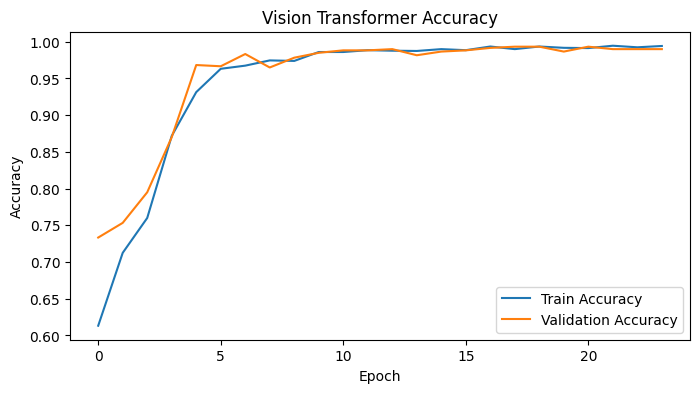

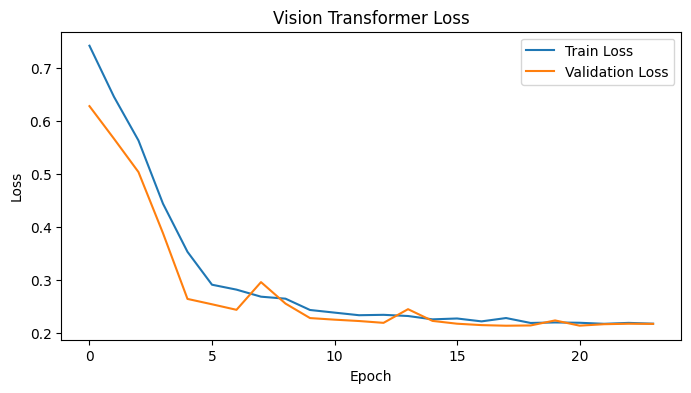

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step

ViT Validation Confusion Matrix classification report:
              precision    recall  f1-score   support

 Closed_Eyes       0.99      1.00      0.99       300
   Open_Eyes       1.00      0.99      0.99       300

    accuracy                           0.99       600
   macro avg       0.99      0.99      0.99       600
weighted avg       0.99      0.99      0.99       600



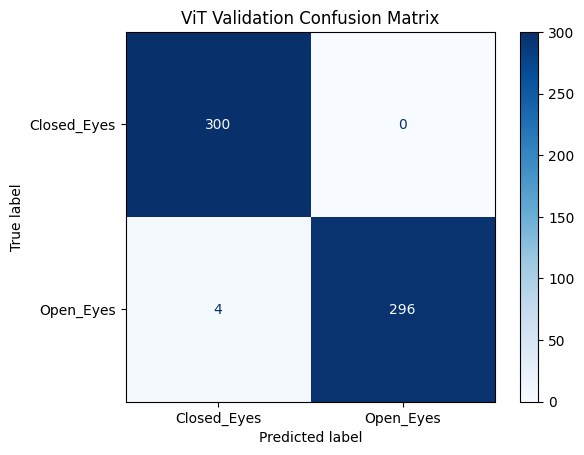

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step

ViT Test Confusion Matrix classification report:
              precision    recall  f1-score   support

 Closed_Eyes       0.98      1.00      0.99       300
   Open_Eyes       1.00      0.98      0.99       300

    accuracy                           0.99       600
   macro avg       0.99      0.99      0.99       600
weighted avg       0.99      0.99      0.99       600



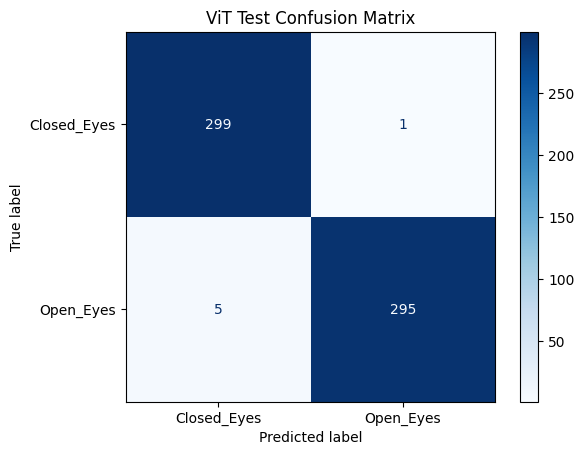

In [53]:
plt.figure(figsize=(8, 4))
plt.plot(vit_history.history["accuracy"], label="Train Accuracy")
plt.plot(vit_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Vision Transformer Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(vit_history.history["loss"], label="Train Loss")
plt.plot(vit_history.history["val_loss"], label="Validation Loss")
plt.title("Vision Transformer Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

vit_val_probs, vit_val_preds, vit_val_report = evaluate_binary_tf_model(vit_model, val_ds_standard, y_val, "ViT Validation Confusion Matrix")
vit_test_probs, vit_test_preds, vit_test_report = evaluate_binary_tf_model(vit_model, test_ds_standard, y_test, "ViT Test Confusion Matrix")

## Report note

The previous YOLOv8 classification section was updated to YOLO12 object detection so that bounding boxes are generated. The original dataset does not include manual bounding-box annotations, so the notebook converts each cropped eye image into a YOLO-format detection sample using one full-image bounding box. EfficientNet and Vision Transformer models were also added as separate deep learning approaches. All three updated/new model sections include overfitting controls such as augmentation, dropout, weight decay/L2 regularisation, reduced learning rate, label smoothing where applicable, and early stopping.

In [ ]:
# import os, zipfile, shutil
# from pathlib import Path

# # Change this only if your zip file has a different name/location.
# ZIP_PATH_ORIGINAL = "/content/drive/MyDrive/CSE427/archive.zip"
# EXTRACT_DIR = "/content/dataset"

# print("Zip exists:", os.path.exists(ZIP_PATH_ORIGINAL))

# if os.path.exists(ZIP_PATH_ORIGINAL):
#     shutil.rmtree(EXTRACT_DIR, ignore_errors=True)
#     os.makedirs(EXTRACT_DIR, exist_ok=True)

#     with zipfile.ZipFile(ZIP_PATH_ORIGINAL, "r") as zip_ref:
#         zip_ref.extractall(EXTRACT_DIR)

#     print("Extracted original dataset to:", EXTRACT_DIR)
# else:
#     raise FileNotFoundError("archive.zip was not found. Put it in MyDrive/CSE427 or change ZIP_PATH_ORIGINAL.")

# # Define the CLASS_FOLDER_TO_ID_MAPPING for the main dataset.
# # This will be used by subsequent cells like yqxWaFu275qF to load data correctly.
# CLASS_FOLDER_TO_ID_MAPPING = {
#     "Closed_Eyes": 0, # Map 'Closed_Eyes' to class ID 0
#     "Open_Eyes": 1    # Map 'Open_Eyes' to class ID 1
# }

## 15. Load External Validation Dataset

In [56]:
EXTERNAL_ZIP_PATH = "/content/drive/MyDrive/CSE427/external_validation.zip"
EXTERNAL_EXTRACT_DIR = "/content/external_dataset"

print("External Zip exists:", os.path.exists(EXTERNAL_ZIP_PATH))

if os.path.exists(EXTERNAL_ZIP_PATH):
    shutil.rmtree(EXTERNAL_EXTRACT_DIR, ignore_errors=True)
    os.makedirs(EXTERNAL_EXTRACT_DIR, exist_ok=True)

    with zipfile.ZipFile(EXTERNAL_ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTERNAL_EXTRACT_DIR)

    print("Extracted external dataset to:", EXTERNAL_EXTRACT_DIR)
else:
    raise FileNotFoundError("external_validation.zip was not found. Put it in MyDrive/CSE427 or change EXTERNAL_ZIP_PATH.")

# Specific mapping for the external dataset folders
CLASS_FOLDER_TO_ID_MAPPING_EXTERNAL = {
    "close_look": 0,
    "forward_look": 1,
    "right_look": 1,
    "left_look": 1
}

EXTERNAL_BASE_PATH = Path(EXTERNAL_EXTRACT_DIR) / "Eye dataset"

print("External dataset base path:", EXTERNAL_BASE_PATH)
print("Path exists:", os.path.exists(EXTERNAL_BASE_PATH))

if not os.path.exists(EXTERNAL_BASE_PATH):
    print(f"Error: External dataset base path '{EXTERNAL_BASE_PATH}' not found.")
    for root, dirs, files in os.walk(EXTERNAL_EXTRACT_DIR):
        print(root, "->", dirs[:10])
    raise ValueError("External dataset base folder not found. Please check EXTERNAL_ZIP_PATH and EXTERNAL_EXTRACT_DIR settings.")

all_external_image_paths = []
all_external_labels = []

# Iterate through the subfolders of the EXTERNAL_BASE_PATH using the external mapping
for folder_name, mapped_label_id in CLASS_FOLDER_TO_ID_MAPPING_EXTERNAL.items():
    class_dir = EXTERNAL_BASE_PATH / folder_name
    if not class_dir.is_dir():
        print(f"Warning: Class directory '{class_dir}' not found. Skipping.")
        continue

    files = sorted([str(p) for p in class_dir.rglob("*") if p.suffix.lower() in valid_exts])
    all_external_image_paths.extend(files)
    all_external_labels.extend([mapped_label_id] * len(files))

all_external_image_paths = np.array(all_external_image_paths)
all_external_labels = np.array(all_external_labels)

# Separate classes for external data
external_closed_eyes_paths = all_external_image_paths[all_external_labels == 0]
external_closed_eyes_labels = all_external_labels[all_external_labels == 0]

external_open_eyes_paths = all_external_image_paths[all_external_labels == 1]
external_open_eyes_labels = all_external_labels[all_external_labels == 1]

# Determine the target count for balancing based on the minimum available images
balance_count_external = min(len(external_closed_eyes_paths), len(external_open_eyes_paths))

# Undersample both classes to match the balance_count_external
if len(external_closed_eyes_paths) > balance_count_external:
    external_closed_eyes_indices = np.random.choice(len(external_closed_eyes_paths), balance_count_external, replace=False)
    external_closed_eyes_paths_balanced = external_closed_eyes_paths[external_closed_eyes_indices]
    external_closed_eyes_labels_balanced = external_closed_eyes_labels[external_closed_eyes_indices]
else:
    external_closed_eyes_paths_balanced = external_closed_eyes_paths
    external_closed_eyes_labels_balanced = external_closed_eyes_labels

if len(external_open_eyes_paths) > balance_count_external:
    external_open_eyes_indices = np.random.choice(len(external_open_eyes_paths), balance_count_external, replace=False)
    external_open_eyes_paths_balanced = external_open_eyes_paths[external_open_eyes_indices]
    external_open_eyes_labels_balanced = external_open_eyes_labels[external_open_eyes_indices]
else:
    external_open_eyes_paths_balanced = external_open_eyes_paths
    external_open_eyes_labels_balanced = external_open_eyes_labels

# Combine the balanced external datasets
external_image_paths = np.concatenate([external_closed_eyes_paths_balanced, external_open_eyes_paths_balanced])
external_labels = np.concatenate([external_closed_eyes_labels_balanced, external_open_eyes_labels_balanced])

# Shuffle the combined dataset to mix the classes
shuffled_indices_external = np.random.permutation(len(external_image_paths))
external_image_paths = external_image_paths[shuffled_indices_external]
external_labels = external_labels[shuffled_indices_external]

print("\nTotal external images after balancing:", len(external_image_paths))
for i, name in enumerate(CLASS_NAMES):
    print(f"{name}: {(external_labels == i).sum()}")

print("Class balance external after balancing:", np.bincount(external_labels))

if len(external_image_paths) == 0:
    raise ValueError("No images found in external validation set after mapping.")

# Ensure both classes are present in the mapped external data.
if len(np.unique(external_labels)) < 2:
    raise ValueError("Not enough unique classes found in external validation set after mapping. Check CLASS_FOLDER_TO_ID_MAPPING_EXTERNAL.")

External Zip exists: True
Extracted external dataset to: /content/external_dataset
External dataset base path: /content/external_dataset/Eye dataset
Path exists: True

Total external images after balancing: 7656
Closed_Eyes: 3828
Open_Eyes: 3828
Class balance external after balancing: [3828 3828]


## 15. Prepare external validation data

In [66]:
# Assuming the 'Eye dataset' folder is the base for external validation.
# If the structure is different, this path needs adjustment.
EXTERNAL_BASE_PATH = Path(EXTERNAL_EXTRACT_DIR) / "Eye dataset"

print("External dataset base path:", EXTERNAL_BASE_PATH)
print("Path exists:", os.path.exists(EXTERNAL_BASE_PATH))

if not os.path.exists(EXTERNAL_BASE_PATH):
    print(f"Error: External dataset base path '{EXTERNAL_BASE_PATH}' not found.")
    for root, dirs, files in os.walk(EXTERNAL_EXTRACT_DIR):
        print(root, "->", dirs[:10])
    raise ValueError("External dataset base folder not found. Please check EXTERNAL_ZIP_PATH and EXTERNAL_EXTRACT_DIR settings.")

# Using the global CLASS_FOLDER_TO_ID_MAPPING defined in cell GUVmwcVl75qE

all_external_image_paths = []
all_external_labels = []

# Iterate through the subfolders of the EXTERNAL_BASE_PATH
for folder_name, mapped_label_id in CLASS_FOLDER_TO_ID_MAPPING_EXTERNAL.items(): # Use external mapping
    class_dir = EXTERNAL_BASE_PATH / folder_name
    if not class_dir.is_dir():
        print(f"Warning: Class directory '{class_dir}' not found. Skipping.")
        continue

    files = sorted([str(p) for p in class_dir.rglob("*") if p.suffix.lower() in valid_exts])
    all_external_image_paths.extend(files)
    all_external_labels.extend([mapped_label_id] * len(files))

all_external_image_paths = np.array(all_external_image_paths)
all_external_labels = np.array(all_external_labels)

# Separate classes for external data
external_closed_eyes_paths = all_external_image_paths[all_external_labels == 0]
external_closed_eyes_labels = all_external_labels[all_external_labels == 0]

external_open_eyes_paths = all_external_image_paths[all_external_labels == 1]
external_open_eyes_labels = all_external_labels[all_external_labels == 1]

# Determine the target count for balancing (3828 for each class)
balance_count = 3828

# Check if the number of closed eyes images is less than the balance_count
if len(external_closed_eyes_paths) < balance_count:
    print(f"Warning: External 'Closed_Eyes' class has fewer images ({len(external_closed_eyes_paths)}) than the target balance_count ({balance_count}). Using the available count for balancing.")
    balance_count = len(external_closed_eyes_paths)

# Undersample the 'Open_Eyes' class to match the balance_count
if len(external_open_eyes_paths) > balance_count:
    external_open_eyes_indices = np.random.choice(len(external_open_eyes_paths), balance_count, replace=False)
    external_open_eyes_paths_balanced = external_open_eyes_paths[external_open_eyes_indices]
    external_open_eyes_labels_balanced = external_open_eyes_labels[external_open_eyes_indices]
else:
    external_open_eyes_paths_balanced = external_open_eyes_paths
    external_open_eyes_labels_balanced = external_open_eyes_labels

# Combine the balanced external datasets
external_image_paths = np.concatenate([external_closed_eyes_paths, external_open_eyes_paths_balanced])
external_labels = np.concatenate([external_closed_eyes_labels, external_open_eyes_labels_balanced])

# Shuffle the combined dataset to mix the classes
shuffled_indices_external = np.random.permutation(len(external_image_paths))
external_image_paths = external_image_paths[shuffled_indices_external]
external_labels = external_labels[shuffled_indices_external]

print("\nTotal external images after balancing:", len(external_image_paths))
for i, name in enumerate(CLASS_NAMES):
    print(f"{name}: {(external_labels == i).sum()}")

print("Class balance external after balancing:", np.bincount(external_labels))

if len(external_image_paths) == 0:
    raise ValueError("No images found in external validation set after mapping.")

# Ensure both classes are present in the mapped external data.
if len(np.unique(external_labels)) < 2:
    raise ValueError("Not enough unique classes found in external validation set after mapping. Check CLASS_FOLDER_TO_ID_MAPPING_EXTERNAL.")

External dataset base path: /content/external_dataset/Eye dataset
Path exists: True

Total external images after balancing: 7656
Closed_Eyes: 3828
Open_Eyes: 3828
Class balance external after balancing: [3828 3828]


## 16. Evaluate EfficientNetB0 on external validation data

Evaluating EfficientNetB0 on external validation set...
240/240 ━━━━━━━━━━━━━━━━━━━━ 9s 33ms/step

EfficientNetB0 External Validation Confusion Matrix classification report:
              precision    recall  f1-score   support

 Closed_Eyes       0.57      1.00      0.73      3828
   Open_Eyes       0.99      0.26      0.41      3828

    accuracy                           0.63      7656
   macro avg       0.78      0.63      0.57      7656
weighted avg       0.78      0.63      0.57      7656



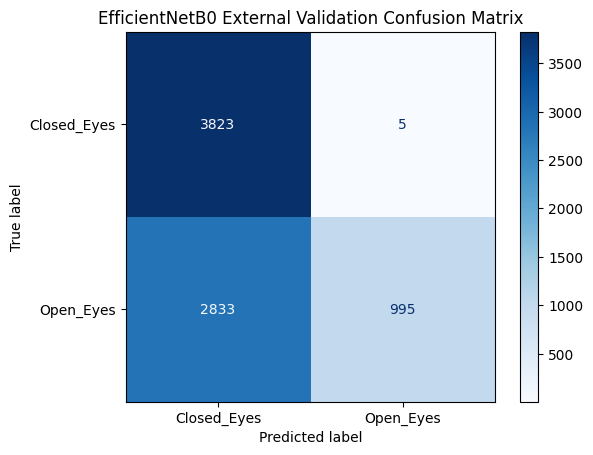

In [67]:
# Create dataset for EfficientNetB0
external_ds_efficientnet = make_standard_dataset(external_image_paths, external_labels)

print("Evaluating EfficientNetB0 on external validation set...")
efficientnet_external_probs, efficientnet_external_preds, efficientnet_external_report = evaluate_binary_tf_model(
    efficientnet_model,
    external_ds_efficientnet,
    external_labels,
    "EfficientNetB0 External Validation Confusion Matrix"
)

## 17. Evaluate Vision Transformer on external validation data

Evaluating Vision Transformer on external validation set...
240/240 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step

ViT External Validation Confusion Matrix classification report:
              precision    recall  f1-score   support

 Closed_Eyes       0.82      0.94      0.88      3828
   Open_Eyes       0.93      0.79      0.86      3828

    accuracy                           0.87      7656
   macro avg       0.88      0.87      0.87      7656
weighted avg       0.88      0.87      0.87      7656



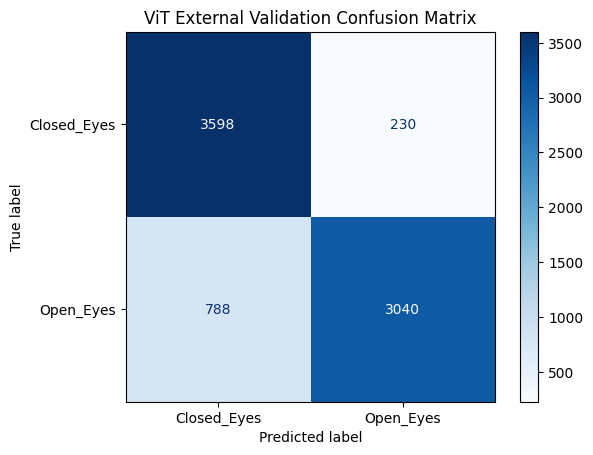

In [68]:
# Create dataset for Vision Transformer
external_ds_vit = make_standard_dataset(external_image_paths, external_labels)

print("Evaluating Vision Transformer on external validation set...")
vit_external_probs, vit_external_preds, vit_external_report = evaluate_binary_tf_model(
    vit_model,
    external_ds_vit,
    external_labels,
    "ViT External Validation Confusion Matrix"
)

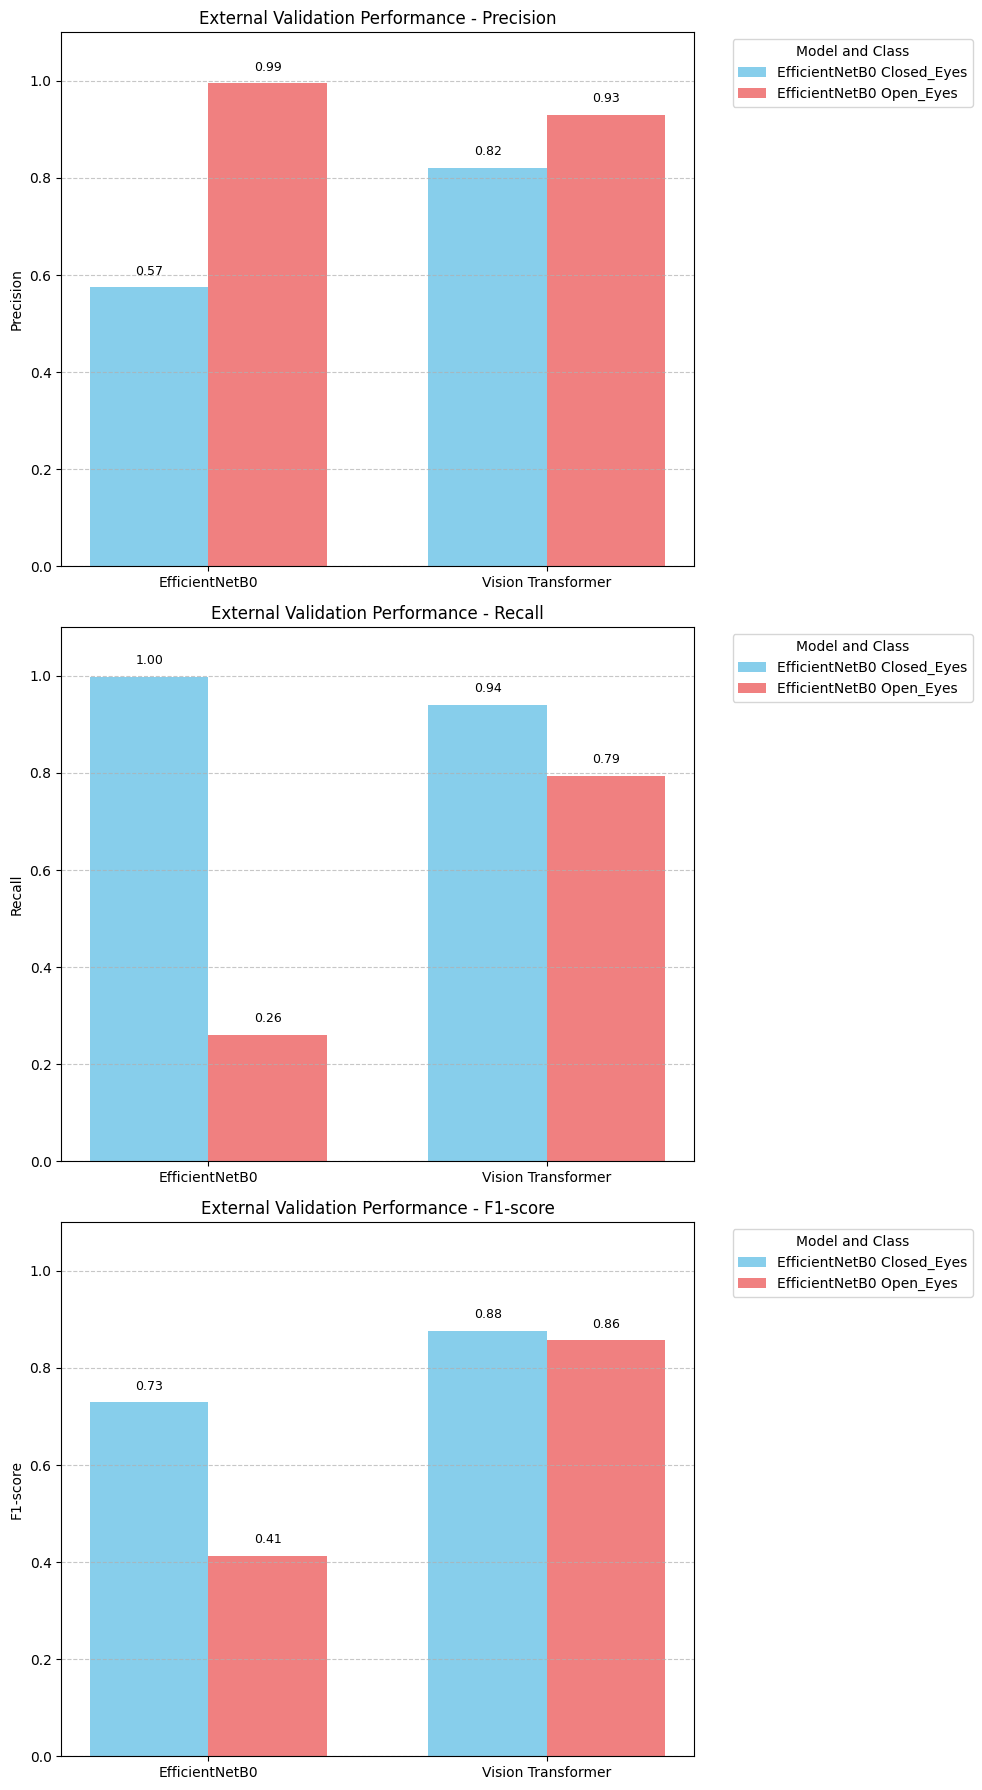

In [69]:
import matplotlib.pyplot as plt
import numpy as np

def plot_model_comparison(report1, model1_name, report2, model2_name, class_names, metric_types=['precision', 'recall', 'f1-score'], title='Model Performance Comparison'):
    fig, axes = plt.subplots(len(metric_types), 1, figsize=(10, 6 * len(metric_types)))
    if len(metric_types) == 1:
        axes = [axes]

    x = np.arange(len(class_names))
    bar_width = 0.35

    for i, metric_type in enumerate(metric_types):
        ax = axes[i]
        metric_values1_closed = report1['Closed_Eyes'][metric_type]
        metric_values1_open = report1['Open_Eyes'][metric_type]

        metric_values2_closed = report2['Closed_Eyes'][metric_type]
        metric_values2_open = report2['Open_Eyes'][metric_type]

        closed_eyes_data = [metric_values1_closed, metric_values2_closed]
        open_eyes_data = [metric_values1_open, metric_values2_open]

        # Plot bars for Closed_Eyes
        ax.bar(x - bar_width/2, closed_eyes_data, bar_width, label=f'{model1_name} {class_names[0]}', color='skyblue')
        ax.bar(x + bar_width/2, open_eyes_data, bar_width, label=f'{model1_name} {class_names[1]}', color='lightcoral')

        # Adding metric values on top of the bars for Model 1
        for j, val in enumerate(closed_eyes_data):
            ax.text(x[j] - bar_width/2, val + 0.02, f'{val:.2f}', ha='center', va='bottom', fontsize=9)
        for j, val in enumerate(open_eyes_data):
            ax.text(x[j] + bar_width/2, val + 0.02, f'{val:.2f}', ha='center', va='bottom', fontsize=9)

        ax.set_ylabel(metric_type.capitalize())
        ax.set_title(f'{title} - {metric_type.capitalize()}')
        ax.set_xticks(x)
        ax.set_xticklabels([model1_name, model2_name])
        ax.set_ylim(0, 1.1) # Extend y-limit to accommodate labels
        ax.legend(title='Model and Class', bbox_to_anchor=(1.05, 1), loc='upper left')
        ax.grid(axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

# Assuming efficientnet_external_report and vit_external_report are available from previous cells
# And CLASS_NAMES is defined as ["Closed_Eyes", "Open_Eyes"]

plot_model_comparison(
    efficientnet_external_report,
    "EfficientNetB0",
    vit_external_report,
    "Vision Transformer",
    CLASS_NAMES,
    title="External Validation Performance"
)

### Visualizing all classification metrics

Plotting classification metrics for EfficientNetB0...


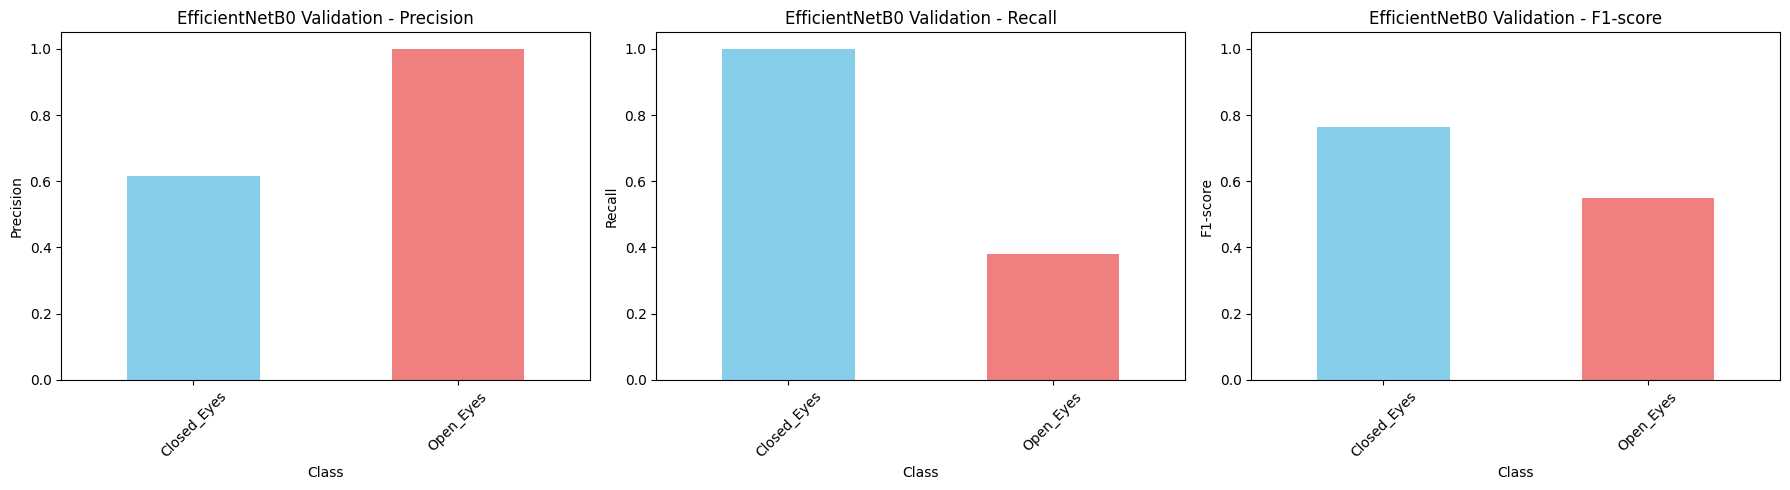

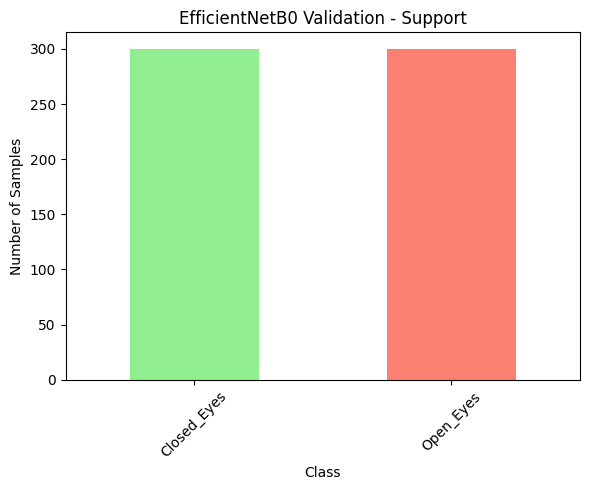

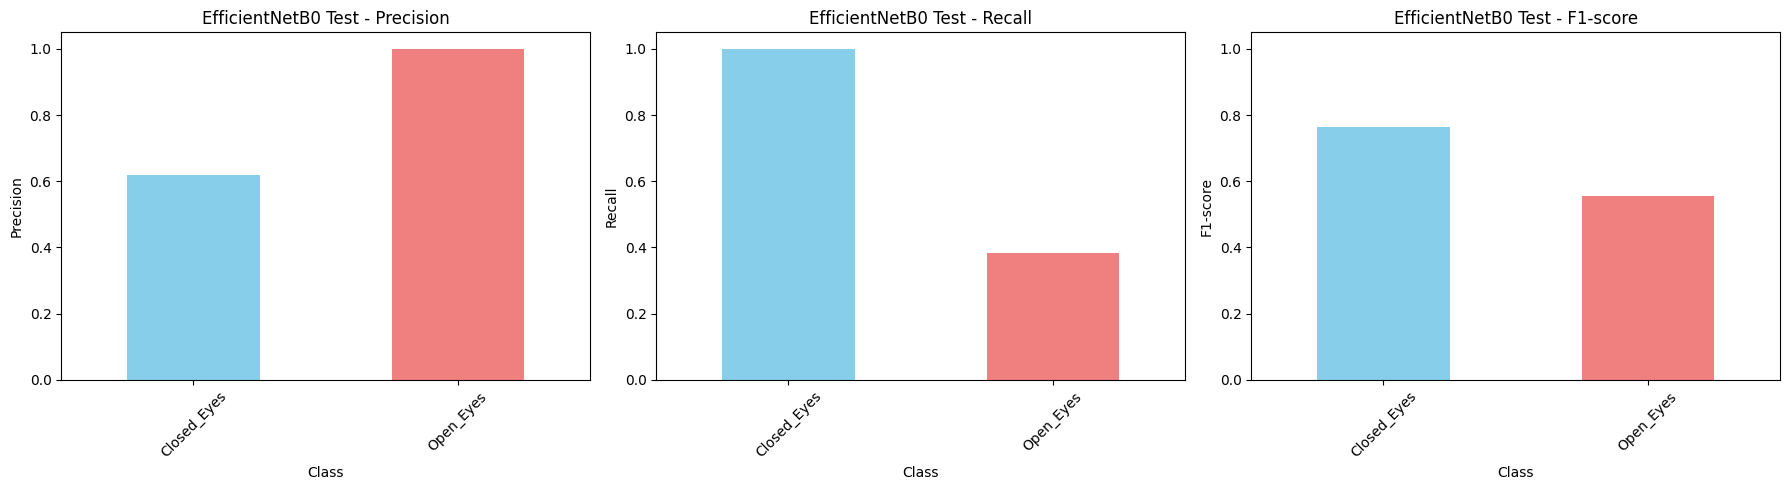

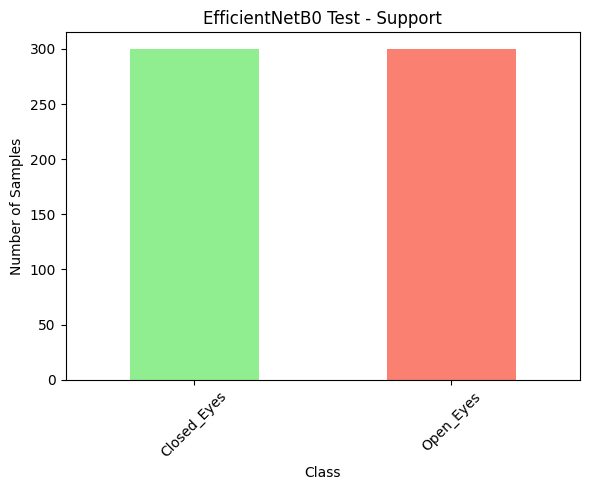

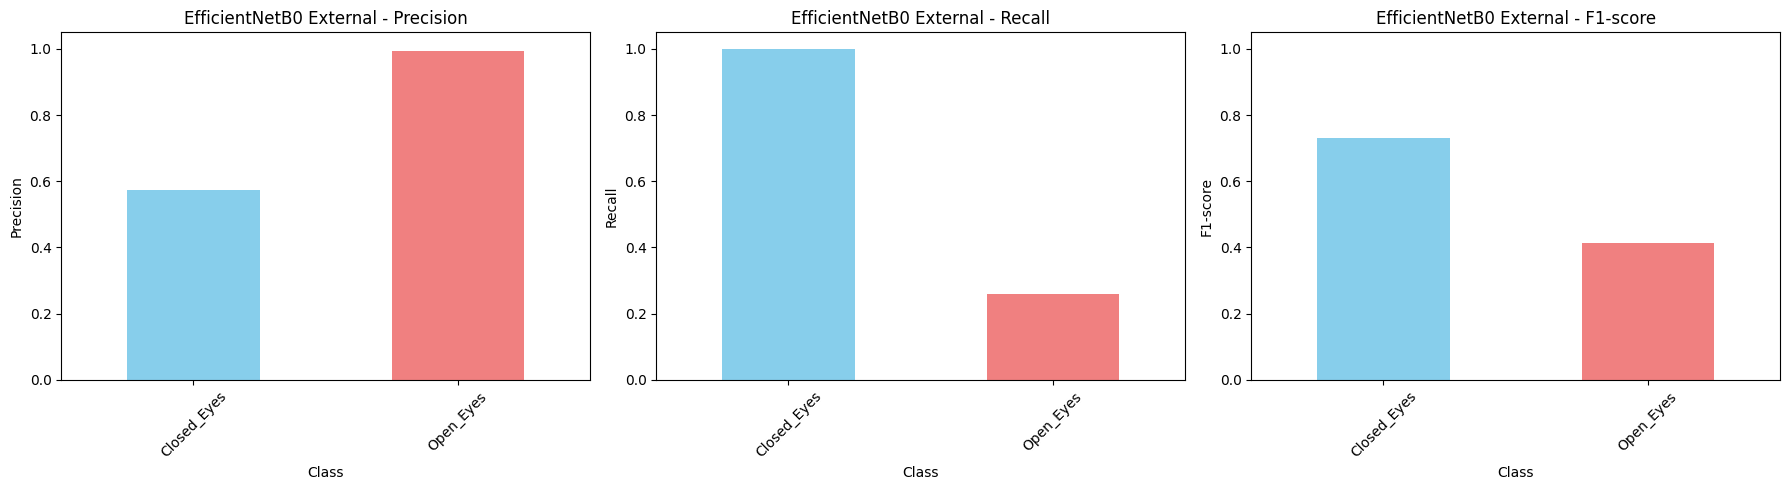

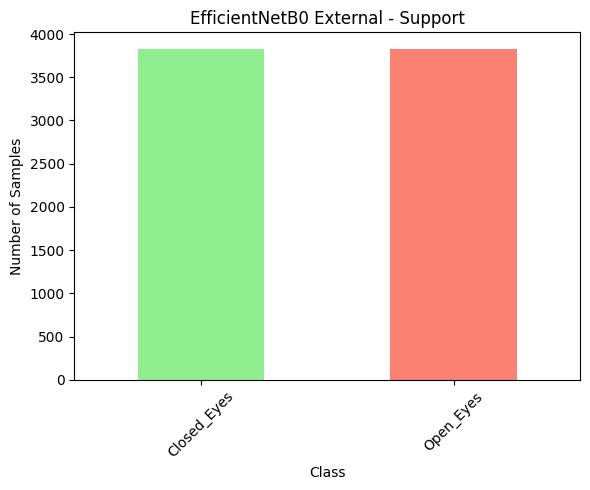


Plotting classification metrics for Vision Transformer...


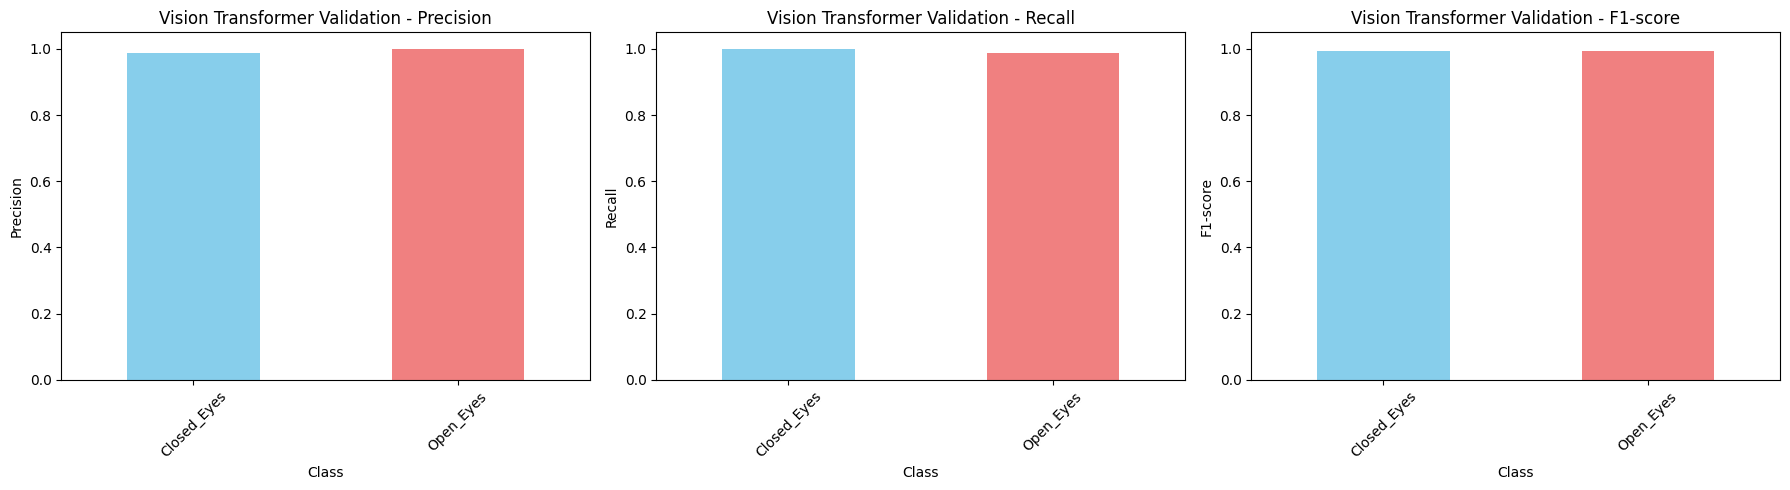

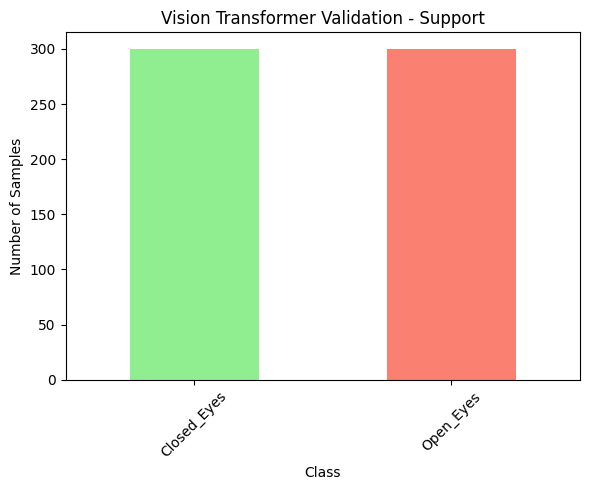

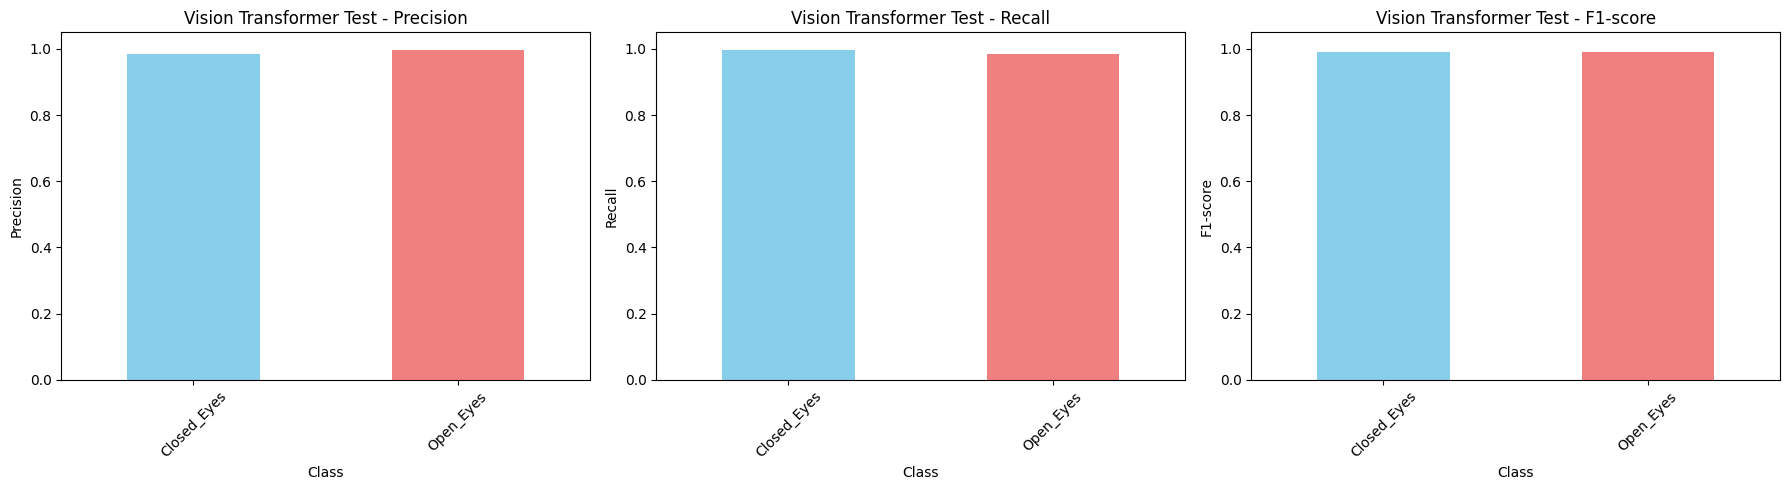

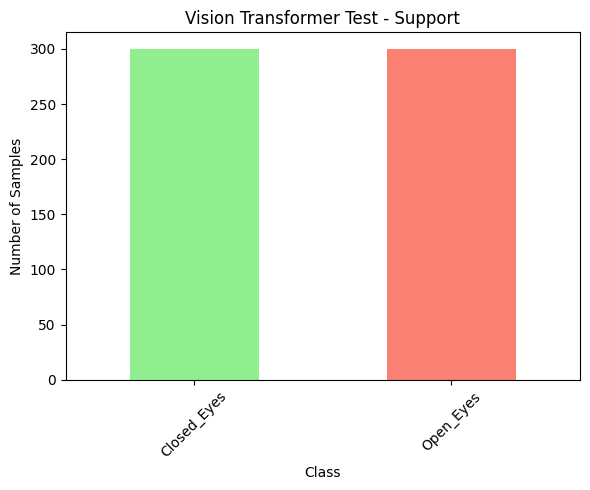

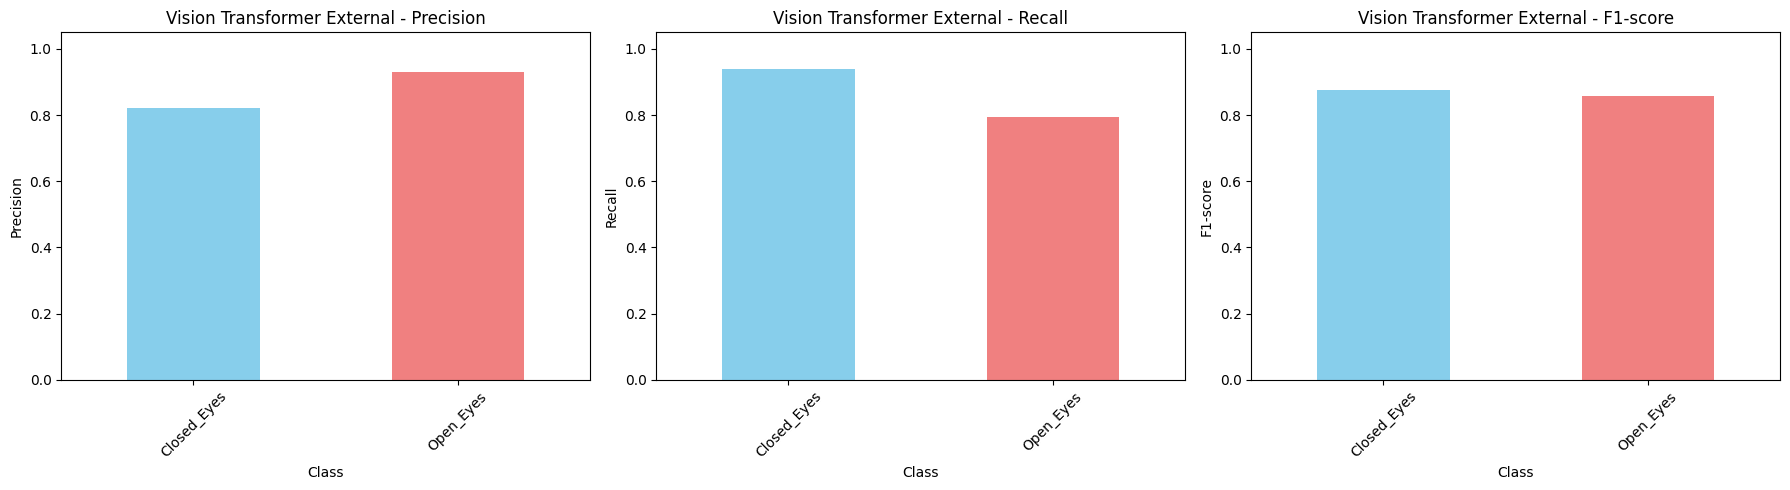

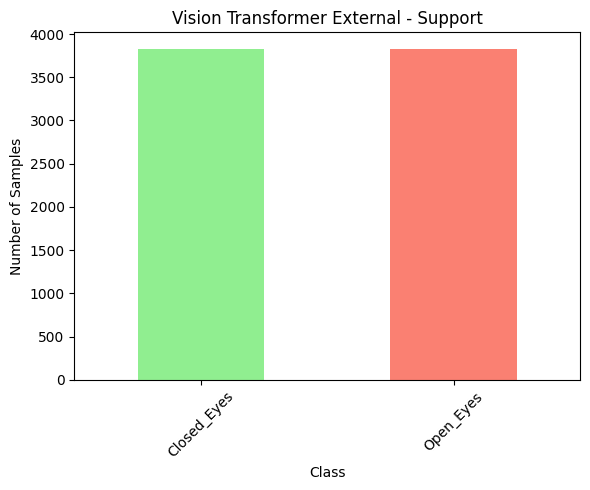

In [70]:
def plot_classification_report_metrics(report_dict, title, class_names=None):
    """
    Plots precision, recall, f1-score, and support from a classification report dictionary.
    """
    # Ensure class_names are correctly ordered if provided, otherwise use keys from report
    if class_names is None:
        # Exclude aggregate keys for plotting individual classes
        class_names = [k for k in report_dict.keys() if k not in ['accuracy', 'macro avg', 'weighted avg']]

    metrics_data = {metric: [report_dict[cls][metric] for cls in class_names] for metric in ['precision', 'recall', 'f1-score']}
    support_data = [report_dict[cls]['support'] for cls in class_names]

    metrics_df = pd.DataFrame(metrics_data, index=class_names)
    support_series = pd.Series(support_data, index=class_names)

    # Plot Precision, Recall, F1-Score
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    metrics = ['precision', 'recall', 'f1-score']
    for i, metric in enumerate(metrics):
        metrics_df[metric].plot(kind='bar', ax=axes[i], color=['skyblue', 'lightcoral'])
        axes[i].set_title(f'{title} - {metric.capitalize()}')
        axes[i].set_ylabel(metric.capitalize())
        axes[i].set_xlabel('Class')
        axes[i].tick_params(axis='x', rotation=45)
        axes[i].set_ylim(0, 1.05)
    plt.tight_layout()
    plt.show()

    # Plot Support
    plt.figure(figsize=(6, 5))
    support_series.plot(kind='bar', color=['lightgreen', 'salmon'])
    plt.title(f'{title} - Support')
    plt.ylabel('Number of Samples')
    plt.xlabel('Class')
    plt.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.show()

print("Plotting classification metrics for EfficientNetB0...")
plot_classification_report_metrics(efficientnet_val_report, "EfficientNetB0 Validation")
plot_classification_report_metrics(efficientnet_test_report, "EfficientNetB0 Test")
plot_classification_report_metrics(efficientnet_external_report, "EfficientNetB0 External")

print("\nPlotting classification metrics for Vision Transformer...")
plot_classification_report_metrics(vit_val_report, "Vision Transformer Validation")
plot_classification_report_metrics(vit_test_report, "Vision Transformer Test")
plot_classification_report_metrics(vit_external_report, "Vision Transformer External")

## 18. Evaluate YOLO12 on external validation data

In [71]:
print("Evaluating YOLO12 on external validation set...")

# Create YOLO format dataset for external validation
YOLO_EXTERNAL_DET_DIR = Path("/content/yolo12_drowsiness_detection_external_dataset")
shutil.rmtree(YOLO_EXTERNAL_DET_DIR, ignore_errors=True)

(YOLO_EXTERNAL_DET_DIR / "images" / "external").mkdir(parents=True, exist_ok=True)
(YOLO_EXTERNAL_DET_DIR / "labels" / "external").mkdir(parents=True, exist_ok=True)

def prepare_yolo_external_detection_split(paths, labels, split_name):
    for src_path, label in zip(paths, labels):
        src_path = Path(src_path)
        class_id = int(label)

        dst_name = f"{CLASS_NAMES[class_id]}_{src_path.stem}{src_path.suffix.lower()}"
        dst_img = YOLO_EXTERNAL_DET_DIR / "images" / split_name / dst_name

        counter = 1
        while dst_img.exists():
            dst_name = f"{CLASS_NAMES[class_id]}_{src_path.stem}_{counter}{src_path.suffix.lower()}"
            dst_img = YOLO_EXTERNAL_DET_DIR / "images" / split_name / dst_name
            counter += 1

        shutil.copy2(src_path, dst_img)

        label_file = YOLO_EXTERNAL_DET_DIR / "labels" / split_name / f"{dst_img.stem}.txt"
        label_file.write_text(f"{class_id} 0.5 0.5 1.0 1.0\n")

prepare_yolo_external_detection_split(external_image_paths, external_labels, "external")

YOLO_EXTERNAL_YAML_PATH = YOLO_EXTERNAL_DET_DIR / "drowsiness_yolo12_external.yaml"
YOLO_EXTERNAL_YAML_PATH.write_text(f"""
path: {YOLO_EXTERNAL_DET_DIR}
train: images/external # Not used for validation, but required by YAML
val: images/external

names:
  0: Closed_Eyes
  1: Open_Eyes
""".strip())

yolo_external_metrics = best_yolo12.val(
    data=str(YOLO_EXTERNAL_YAML_PATH),
    split="val", # Use 'val' split in YOLO, as 'test' is not a default option in val mode with a single split
    imgsz=224,
    batch=16
)
print(yolo_external_metrics)


Evaluating YOLO12 on external validation set...
Ultralytics 8.4.48 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 210.8±164.0 MB/s, size: 6.2 KB)
val: Scanning /content/yolo12_drowsiness_detection_external_dataset/labels/external... 7656 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 7656/7656 2.3Kit/s 3.3s
val: New cache created: /content/yolo12_drowsiness_detection_external_dataset/labels/external.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 479/479 11.2it/s 42.9s
                   all       7656       7656      0.977      0.981      0.994      0.991
           Closed_Eyes       3828       3828      0.993      0.969      0.993      0.991
             Open_Eyes       3828       3828      0.962      0.993      0.994      0.991
Speed: 0.2ms preprocess, 1.8ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /content/runs/detect/v

### Visualizing all classification metrics for YOLO12

Plotting classification metrics for YOLO12...


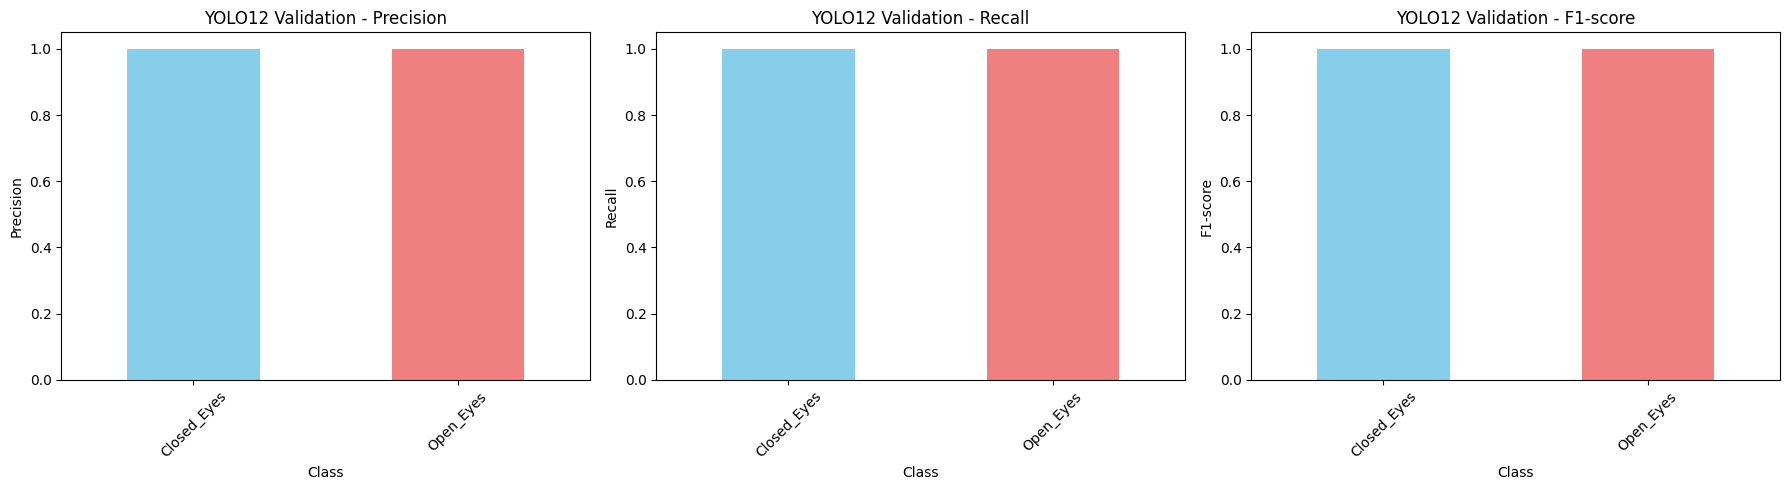

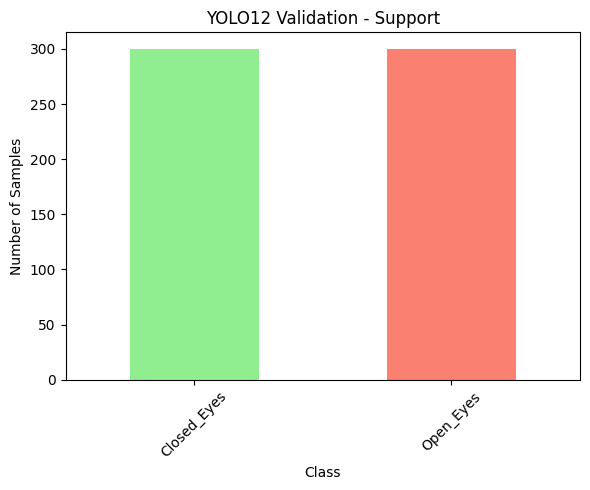

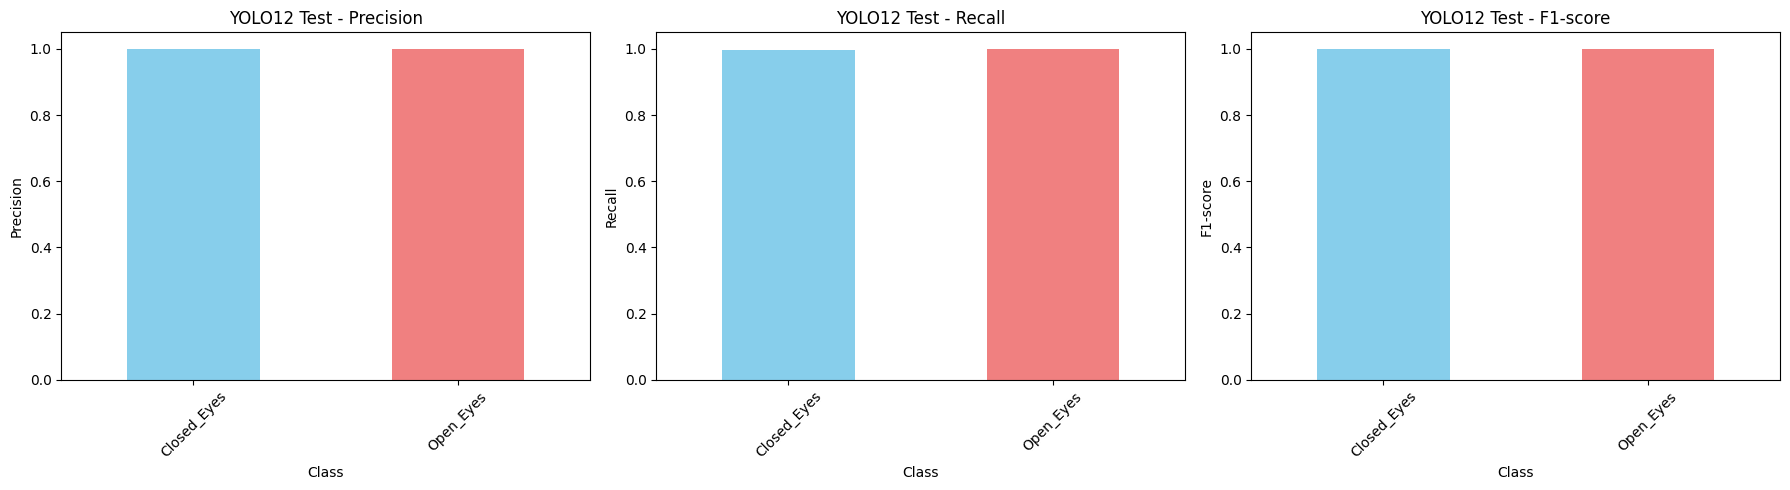

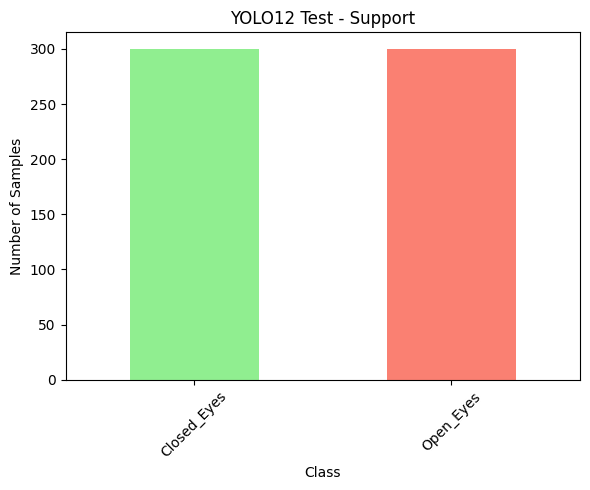

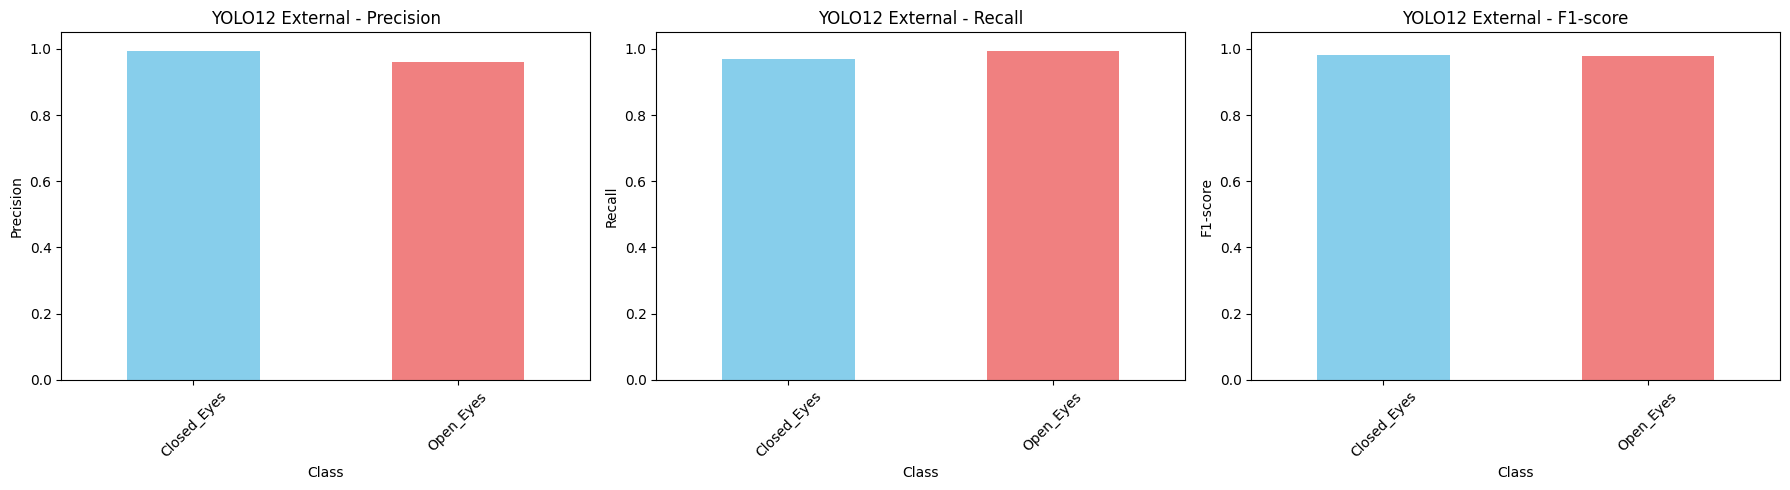

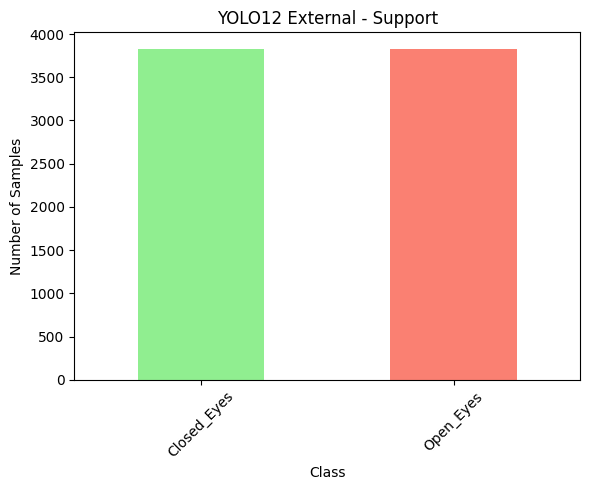

In [72]:
def yolo_metrics_to_classification_report(yolo_metrics_obj, class_names):
    """
    Converts Ultralytics DetMetrics object into a classification report dictionary format.
    """
    report = {}
    if yolo_metrics_obj.ap_class_index is not None:
        for i, cls_idx in enumerate(yolo_metrics_obj.ap_class_index):
            cls_name = class_names[cls_idx]
            # Get class-specific precision and recall from the 'box' attribute
            precision = yolo_metrics_obj.box.p[i]
            recall = yolo_metrics_obj.box.r[i]
            f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

            # For YOLO, support is typically the number of instances for that class.
            support = yolo_metrics_obj.nt_per_class[i]

            report[cls_name] = {
                'precision': precision,
                'recall': recall,
                'f1-score': f1_score,
                'support': support
            }

        # Add aggregate metrics if available (simplified for display)
        report['accuracy'] = yolo_metrics_obj.results_dict.get('metrics/mAP50-95(B)', 0)
        # Note: 'macro avg' and 'weighted avg' would require more complex calculation
        # from per-class metrics. For this visualization, we'll keep it simple.
        macro_precision = sum(report[c]['precision'] for c in class_names) / len(class_names)
        macro_recall = sum(report[c]['recall'] for c in class_names) / len(class_names)
        macro_f1 = sum(report[c]['f1-score'] for c in class_names) / len(class_names)
        report['macro avg'] = {'precision': macro_precision, 'recall': macro_recall, 'f1-score': macro_f1, 'support': sum(yolo_metrics_obj.nt_per_class)}

        weighted_precision = sum(report[c]['precision'] * report[c]['support'] for c in class_names) / sum(report[c]['support'] for c in class_names)
        weighted_recall = sum(report[c]['recall'] * report[c]['support'] for c in class_names) / sum(report[c]['support'] for c in class_names)
        weighted_f1 = sum(report[c]['f1-score'] * report[c]['support'] for c in class_names) / sum(report[c]['support'] for c in class_names)
        report['weighted avg'] = {'precision': weighted_precision, 'recall': weighted_recall, 'f1-score': weighted_f1, 'support': sum(yolo_metrics_obj.nt_per_class)}


    return report


# Generate reports for YOLO12
yolo_val_report_dict = yolo_metrics_to_classification_report(yolo_val_metrics, CLASS_NAMES)
yolo_test_report_dict = yolo_metrics_to_classification_report(yolo_test_metrics, CLASS_NAMES)
yolo_external_report_dict = yolo_metrics_to_classification_report(yolo_external_metrics, CLASS_NAMES)


print("Plotting classification metrics for YOLO12...")
plot_classification_report_metrics(yolo_val_report_dict, "YOLO12 Validation", CLASS_NAMES)
plot_classification_report_metrics(yolo_test_report_dict, "YOLO12 Test", CLASS_NAMES)
plot_classification_report_metrics(yolo_external_report_dict, "YOLO12 External", CLASS_NAMES)


## 19. Visualize Classification Metrics

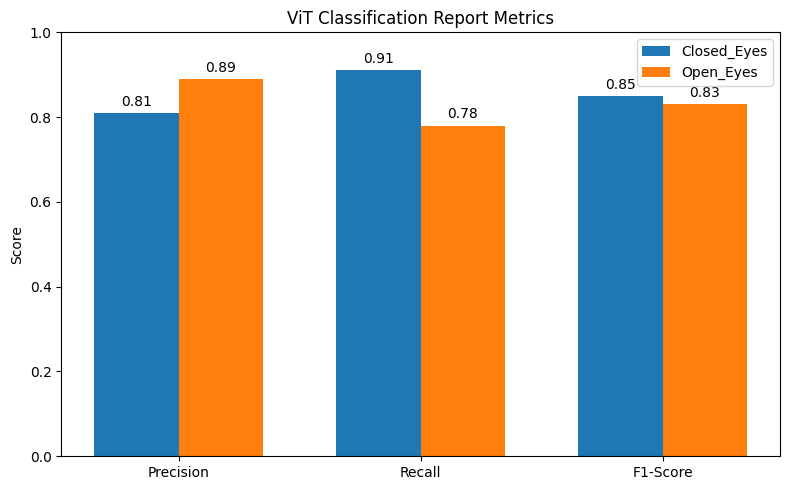

In [73]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Classification report values
metrics = {
    'Closed_Eyes': [0.81, 0.91, 0.85],
    'Open_Eyes': [0.89, 0.78, 0.83]
}

metric_names = ['Precision', 'Recall', 'F1-Score']

# Create DataFrame
df = pd.DataFrame(metrics, index=metric_names)

# Plot settings
x = np.arange(len(metric_names))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

# Bars
bars1 = ax.bar(x - width/2, df['Closed_Eyes'], width, label='Closed_Eyes')
bars2 = ax.bar(x + width/2, df['Open_Eyes'], width, label='Open_Eyes')

# Labels and title
ax.set_ylabel('Score')
ax.set_title('ViT Classification Report Metrics')
ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylim(0, 1.0)
ax.legend()

# Add value labels on top of bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom')

plt.tight_layout()
plt.show()

In [ ]:
#

## 20. Data Characteristics Analysis (Training and Validation)

In [74]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from pathlib import Path

def get_image_characteristics(image_paths, dataset_name):
    """
    Extracts image dimensions (width, height) and average pixel intensity
    for a given list of image paths.
    """
    widths = []
    heights = []
    pixel_intensities = []

    print(f"Processing {dataset_name} dataset...")
    for i, img_path_str in enumerate(image_paths):
        img_path = Path(img_path_str)
        try:
            img = cv2.imread(str(img_path))
            if img is None:
                print(f"Warning: Could not read image at {img_path}. Skipping.")
                continue

            h, w, _ = img.shape
            widths.append(w)
            heights.append(h)

            # Convert to grayscale for pixel intensity calculation
            gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
            pixel_intensities.append(np.mean(gray_img))
        except Exception as e:
            print(f"Error processing image {img_path}: {e}. Skipping.")

        if (i + 1) % 1000 == 0:
            print(f"  Processed {i + 1}/{len(image_paths)} images from {dataset_name}")

    print(f"Finished processing {len(image_paths)} images from {dataset_name}.")
    return widths, heights, pixel_intensities

def plot_distributions(widths, heights, pixel_intensities, title_prefix):
    """
    Plots histograms for image widths, heights, and pixel intensities.
    """
    plt.figure(figsize=(18, 5))

    plt.subplot(1, 3, 1)
    sns.histplot(widths, bins=50, kde=True)
    plt.title(f'{title_prefix} - Image Width Distribution')
    plt.xlabel('Width (pixels)')
    plt.ylabel('Count')

    plt.subplot(1, 3, 2)
    sns.histplot(heights, bins=50, kde=True)
    plt.title(f'{title_prefix} - Image Height Distribution')
    plt.xlabel('Height (pixels)')
    plt.ylabel('Count')

    plt.subplot(1, 3, 3)
    sns.histplot(pixel_intensities, bins=50, kde=True)
    plt.title(f'{title_prefix} - Pixel Intensity Distribution')
    plt.xlabel('Average Pixel Intensity (0-255)')
    plt.ylabel('Count')

    plt.tight_layout()
    plt.show()

Processing Training Dataset dataset...
  Processed 1000/2800 images from Training Dataset
  Processed 2000/2800 images from Training Dataset
Finished processing 2800 images from Training Dataset.


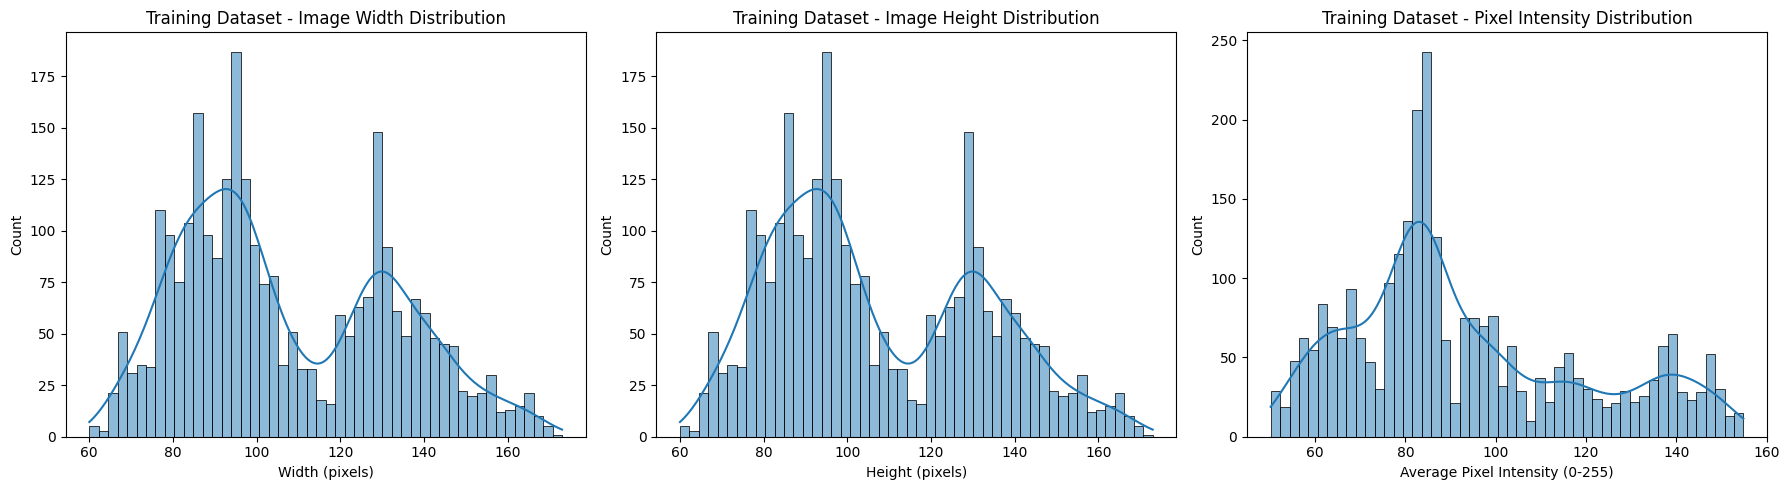

In [75]:
# Analyze and plot for the Training Dataset
train_widths, train_heights, train_pixel_intensities = get_image_characteristics(train_paths, "Training Dataset")
plot_distributions(train_widths, train_heights, train_pixel_intensities, "Training Dataset")

Processing Validation Dataset dataset...
Finished processing 600 images from Validation Dataset.


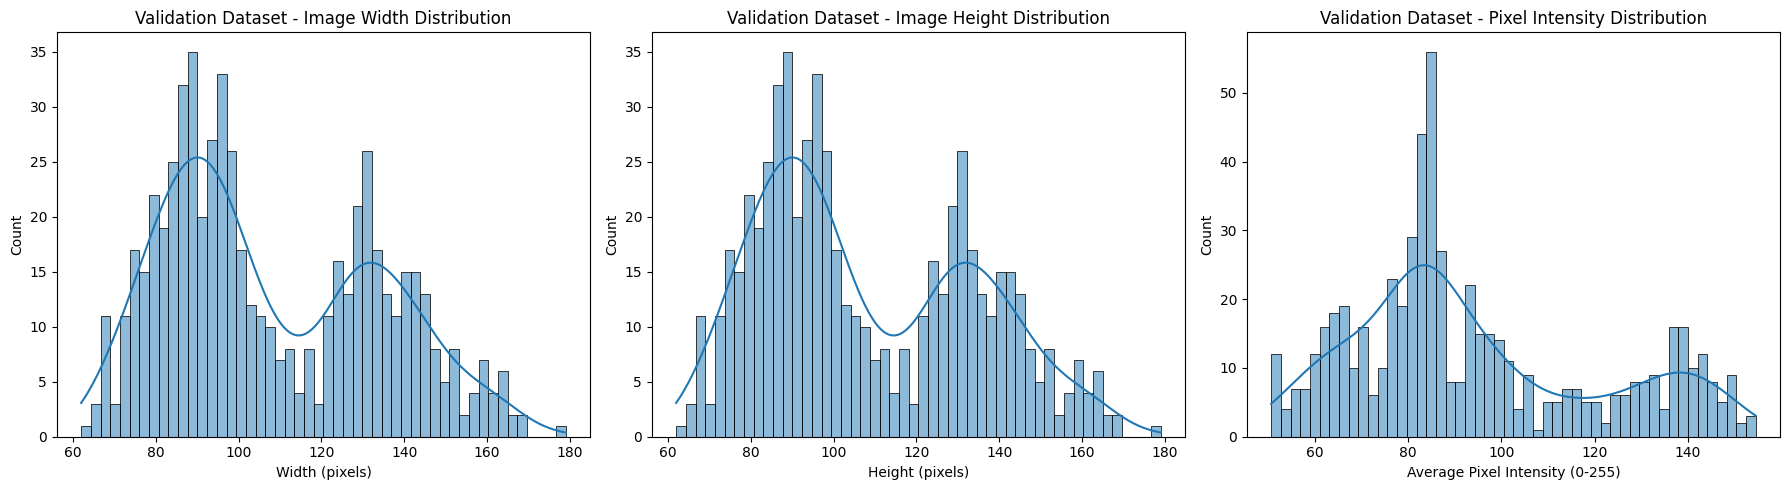

In [76]:
# Analyze and plot for the Validation Dataset
val_widths, val_heights, val_pixel_intensities = get_image_characteristics(val_paths, "Validation Dataset")
plot_distributions(val_widths, val_heights, val_pixel_intensities, "Validation Dataset")